- Measure accuracy for devices
- Home settings

In [1]:
from __future__ import annotations
import pandas as pd 
from typing import Dict, List, Tuple
from pathlib import Path
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re
import numpy as np
from copy import deepcopy
from datetime import datetime
from typing import Any
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

In [2]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [3]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [4]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [5]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)

In [6]:
FEATURE_COLUMNS = [
    "packet_count",
    "total_bytes",
]

DEVICE_COLUMN = "eth.src"          # Replace with "eth.src" if applicable
TIME_COLUMN = "timestamp"
LABEL_COLUMN = "is_iot_device"

KPLITS = 5
RANDOM_STATE = 42
WINDOW_SECONDS = 4

In [7]:
# Outgoing volume
def extract_data_from_pcap(
    file_paths: Iterable[str]
) -> pd.DataFrame:
    columns = [
        "frame.number",
        "frame.time_epoch",
        "frame.len",
        "eth.src",
        "eth.dst",
    ]

    all_data = []

    for file_path in file_paths:
        raw_df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.number": "int32",
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
                "eth.dst": "category",
            }
        )

        raw_df["capture_id"] = Path(file_path).stem
        all_data.append(raw_df)


    res = pd.concat(all_data, ignore_index=True)
    res = res.sort_values(
        ["frame.time_epoch", "eth.src"],
        ignore_index=True,
    )

    return res


In [8]:
all_data = extract_data_from_pcap(csv_files_1)

In [9]:
def label_features(
    features: pd.DataFrame,
    device_mapping: Dict[str, Dict[str, str]]
) -> pd.DataFrame:

    unknown_macs = set(features["eth.src"]) - set(device_mapping)

    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )

    res = features.copy()
    res["is_iot_device"] = res["eth.src"].map(
        lambda x: device_mapping[x]["is_iot_device"]
    )
    res["device_type"] = res["eth.src"].map(
        lambda x: device_mapping[x]["device_type"]
    )
    res["vendor"] = res["eth.src"].map(
        lambda x: device_mapping[x]["vendor"]
    )

    return res

In [10]:
df = all_data.copy()

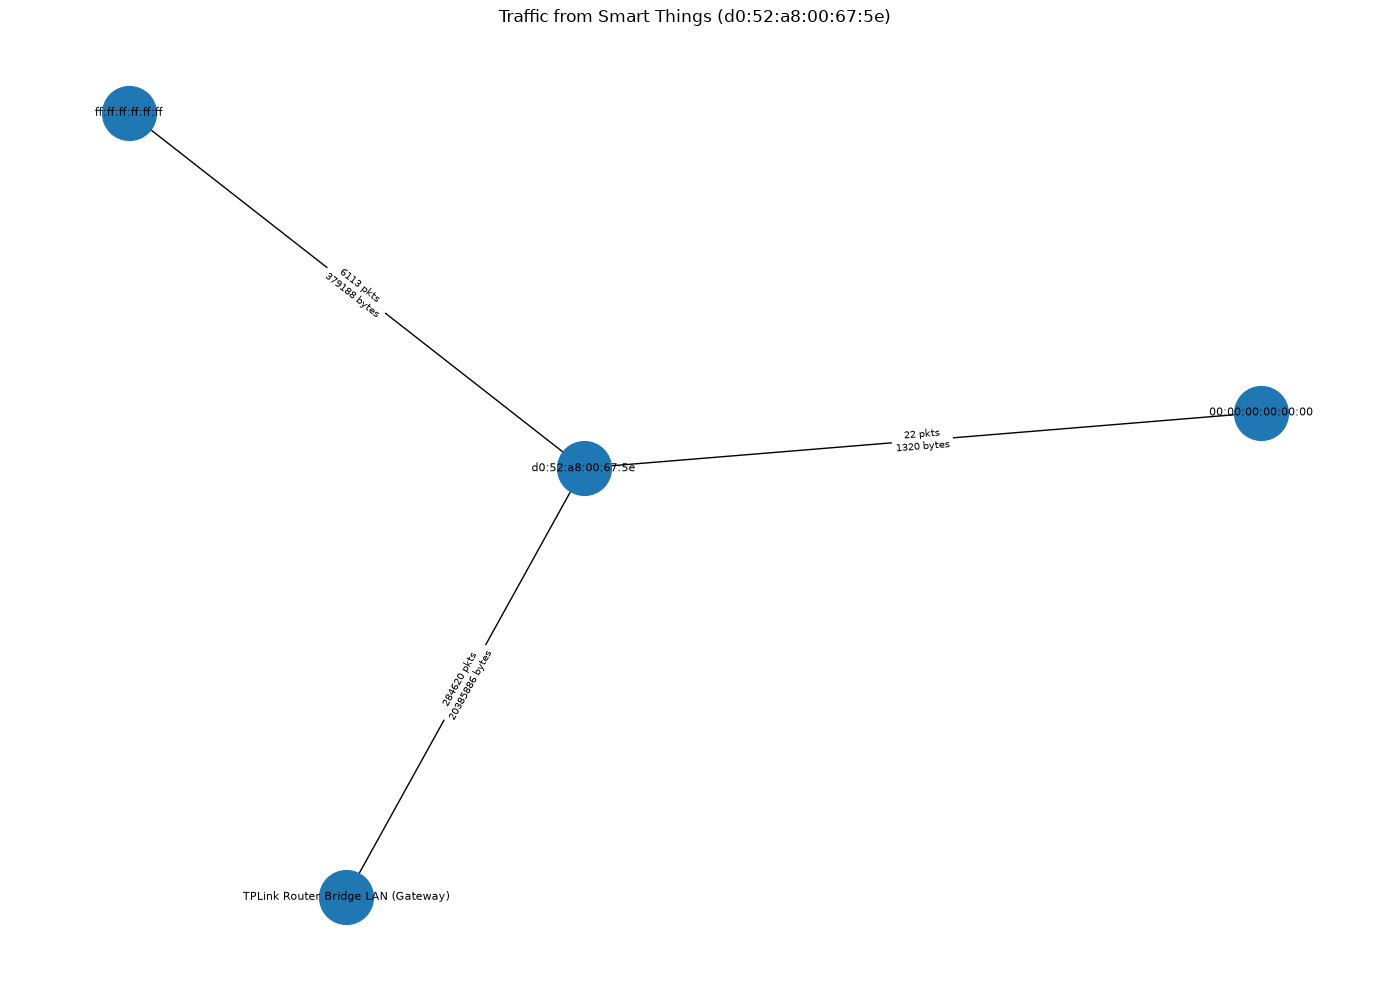

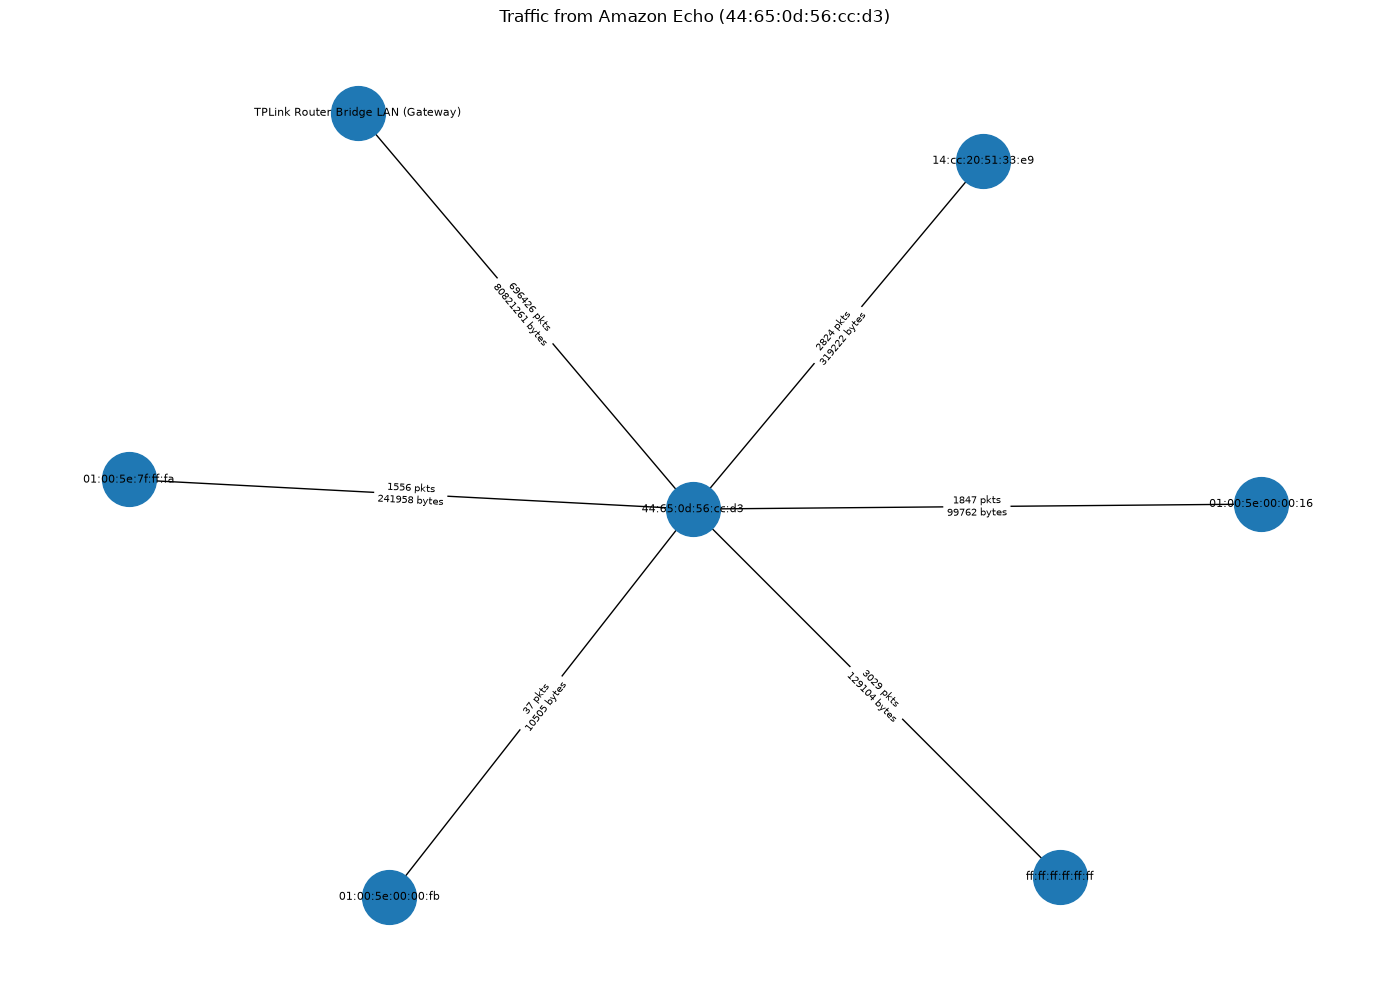

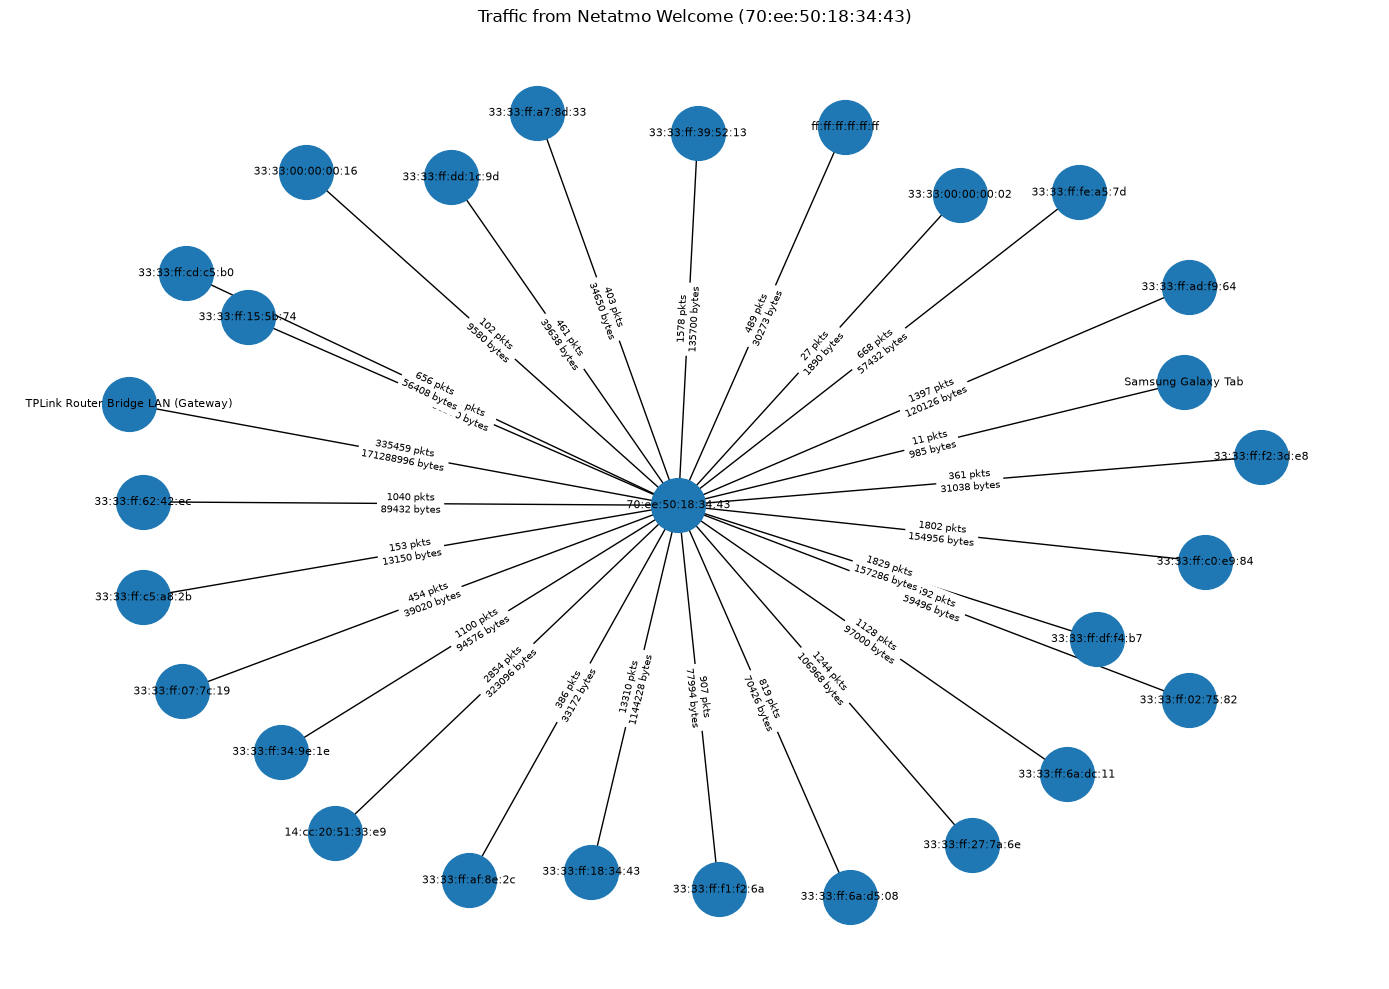

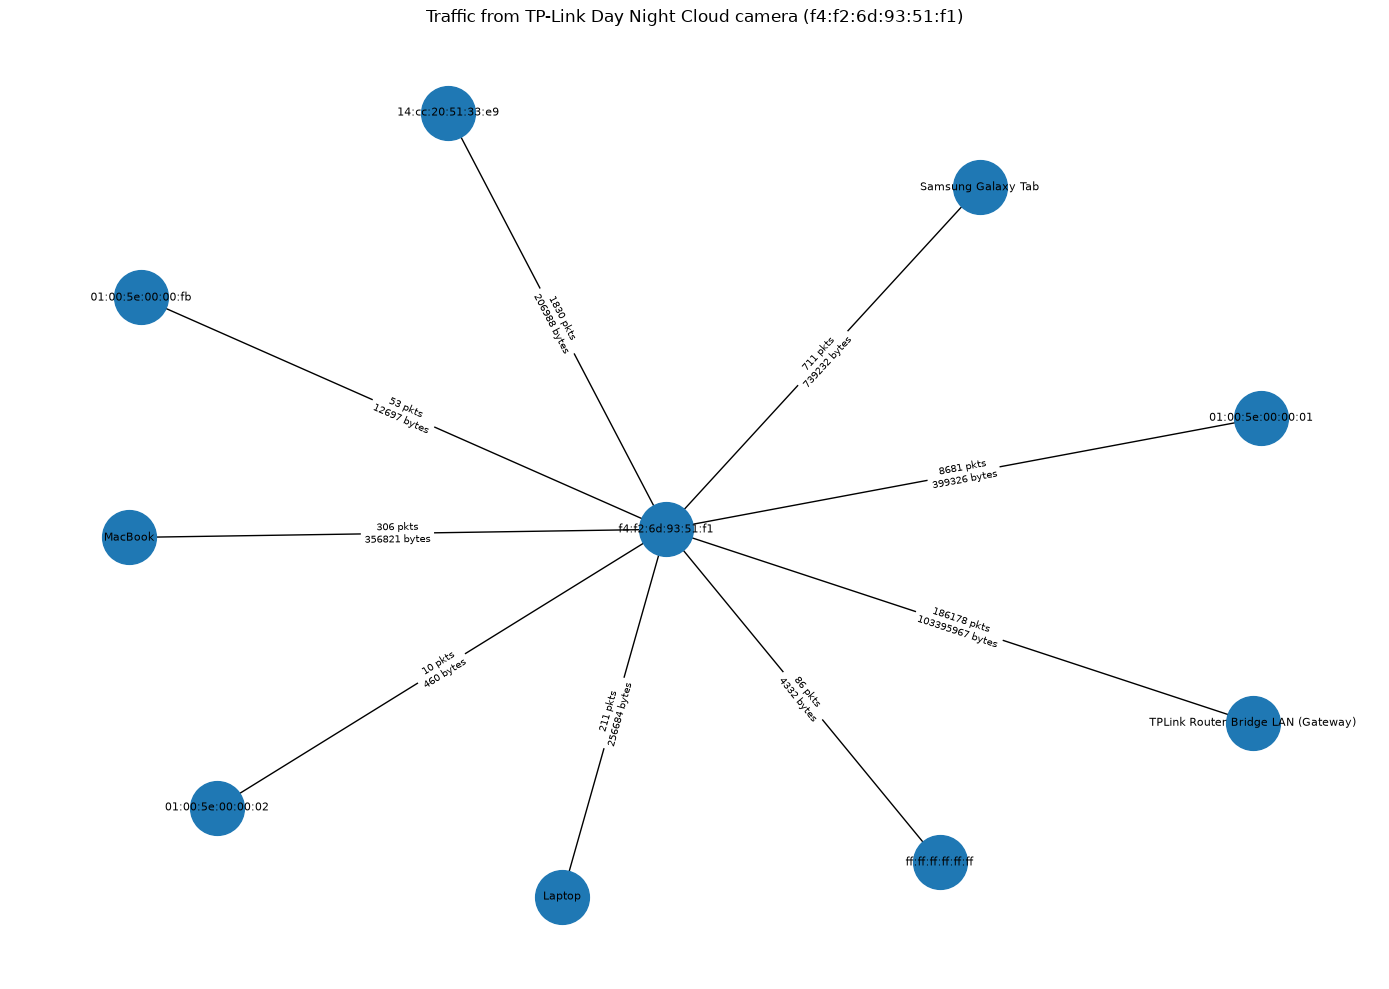

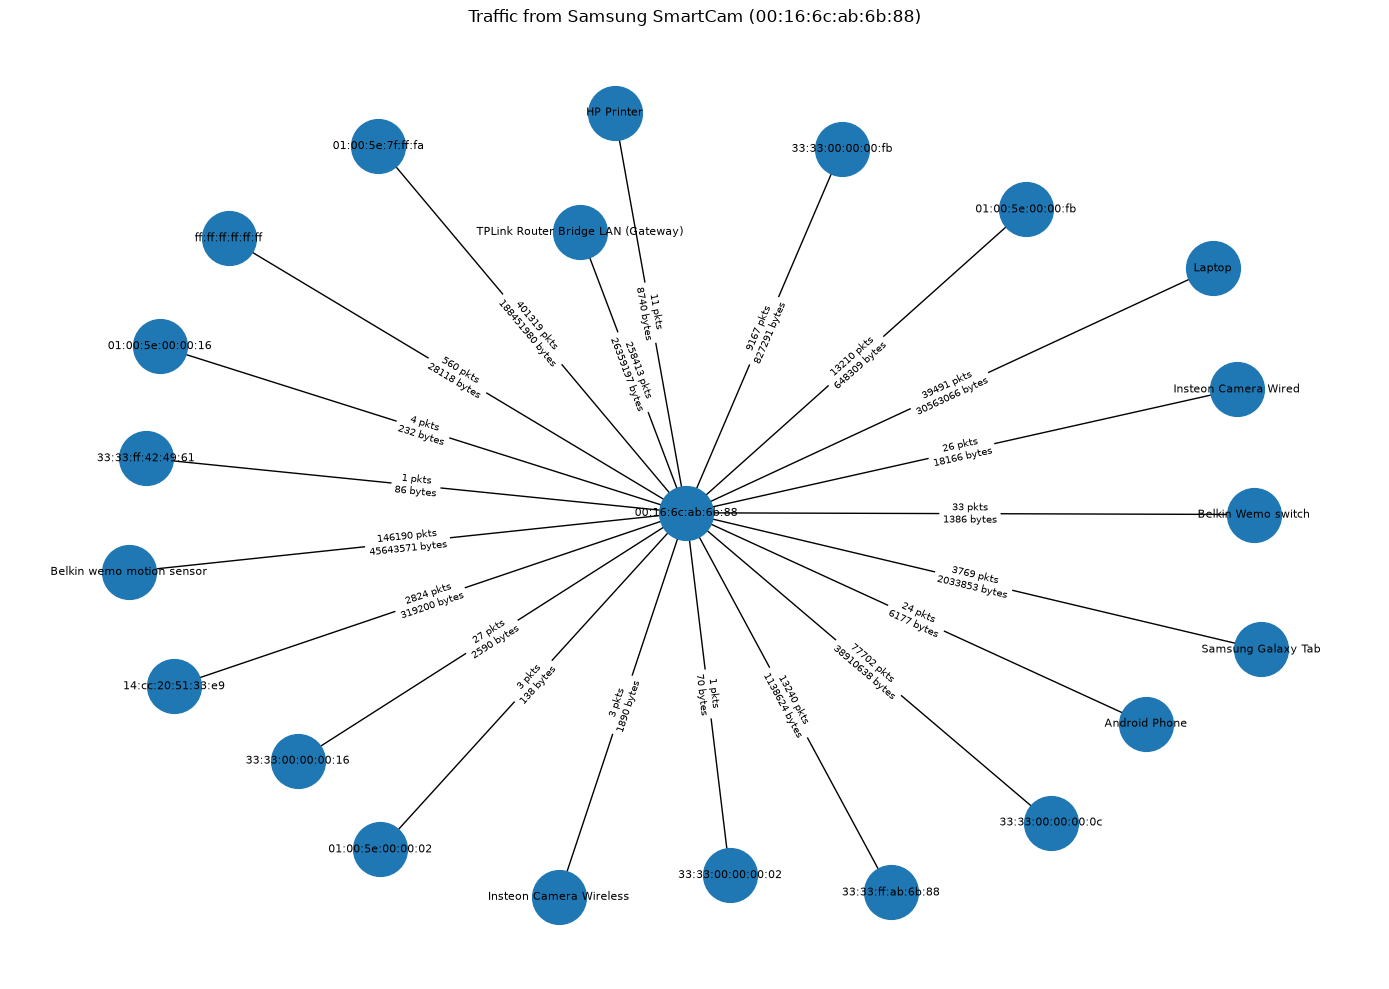

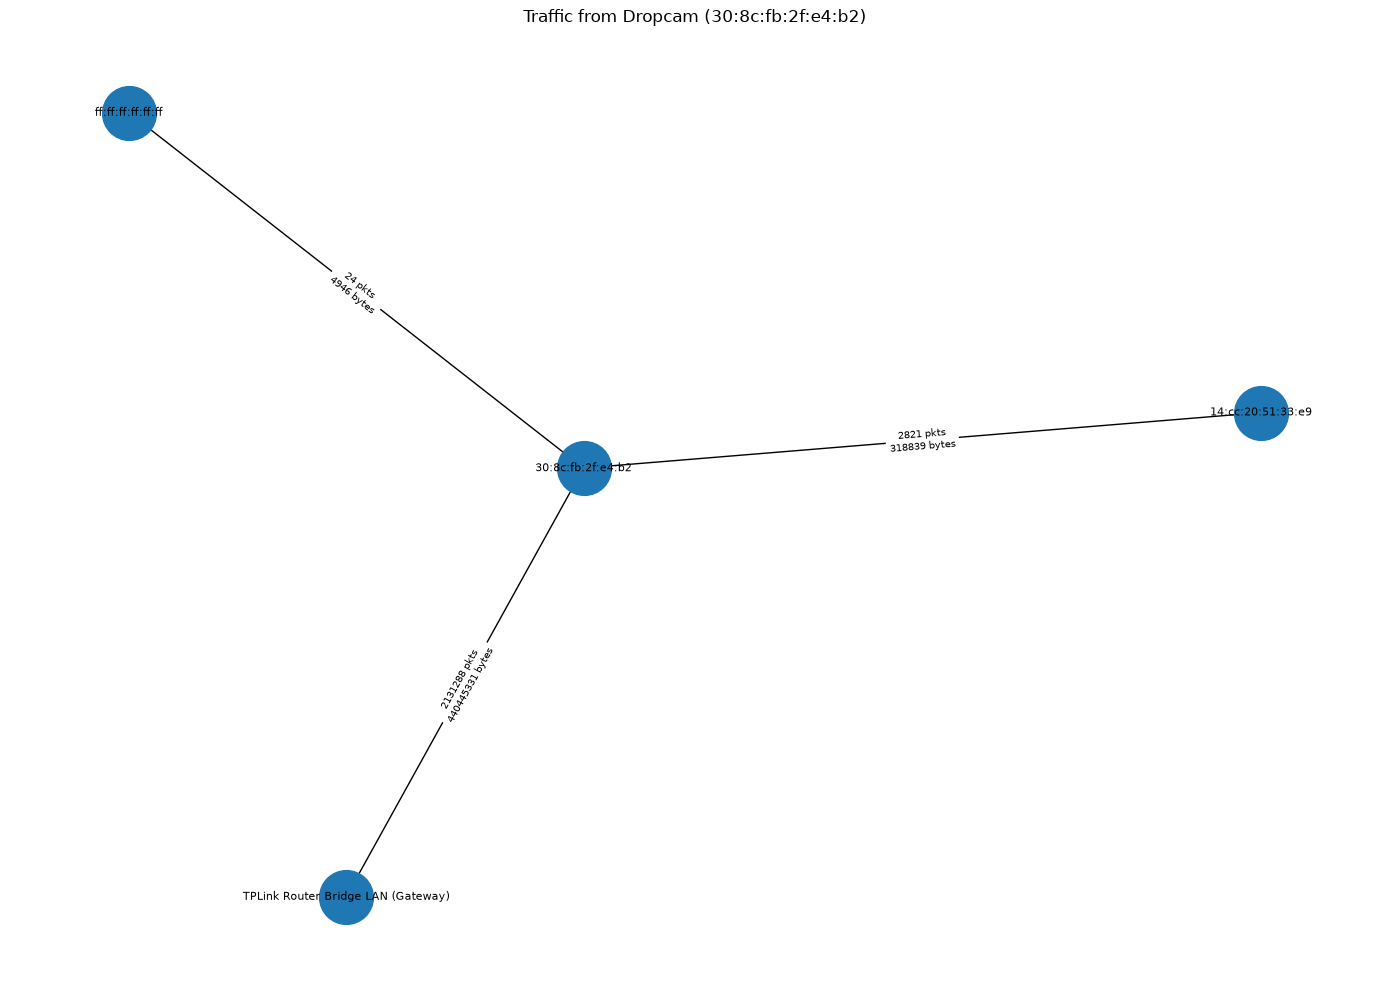

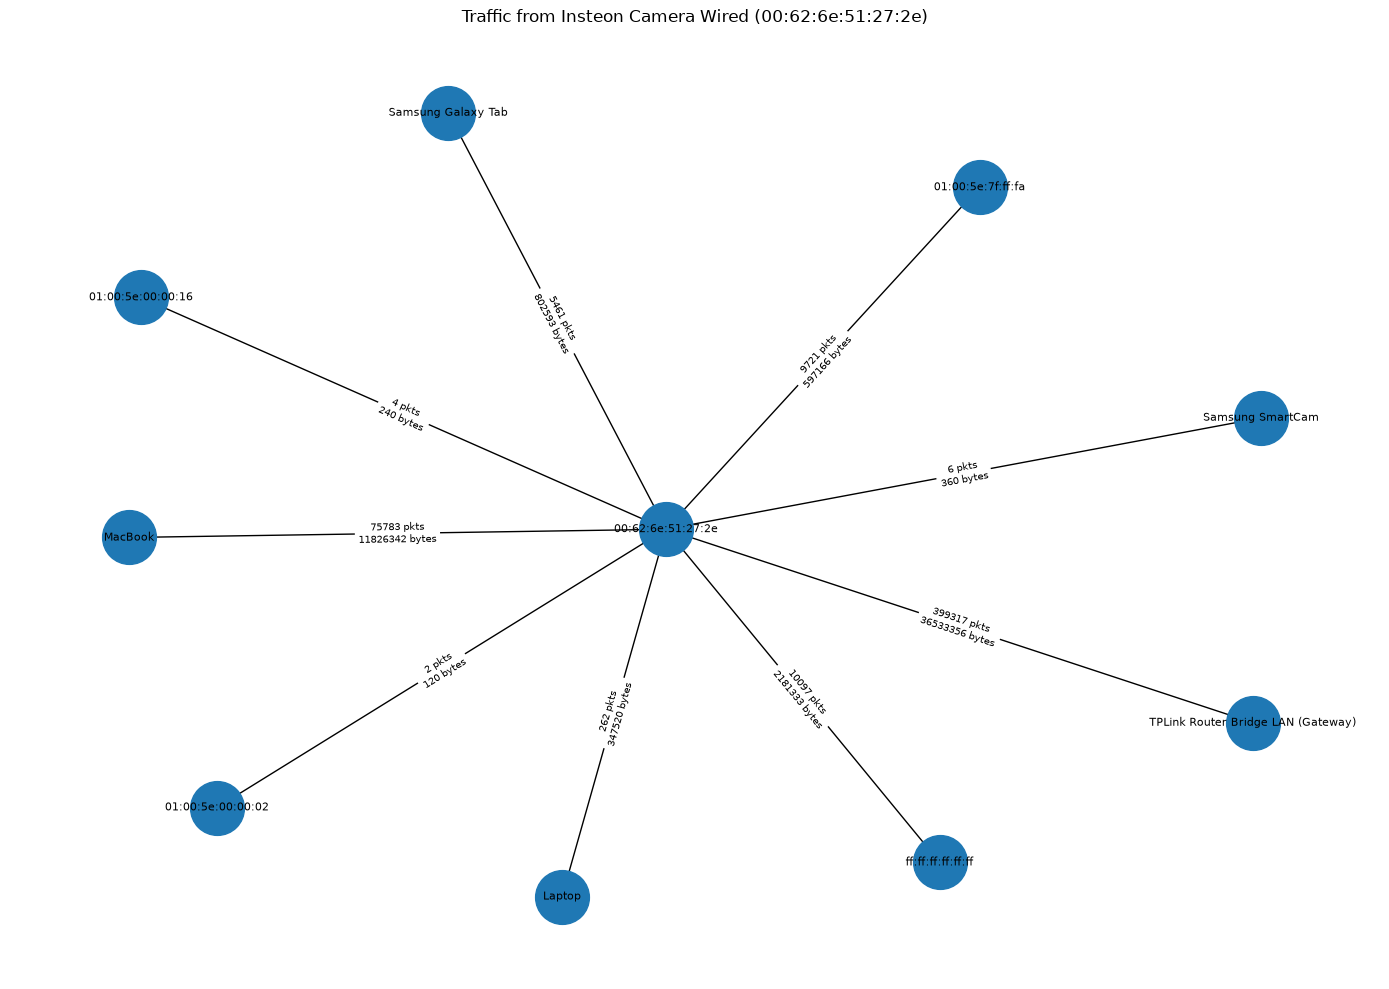

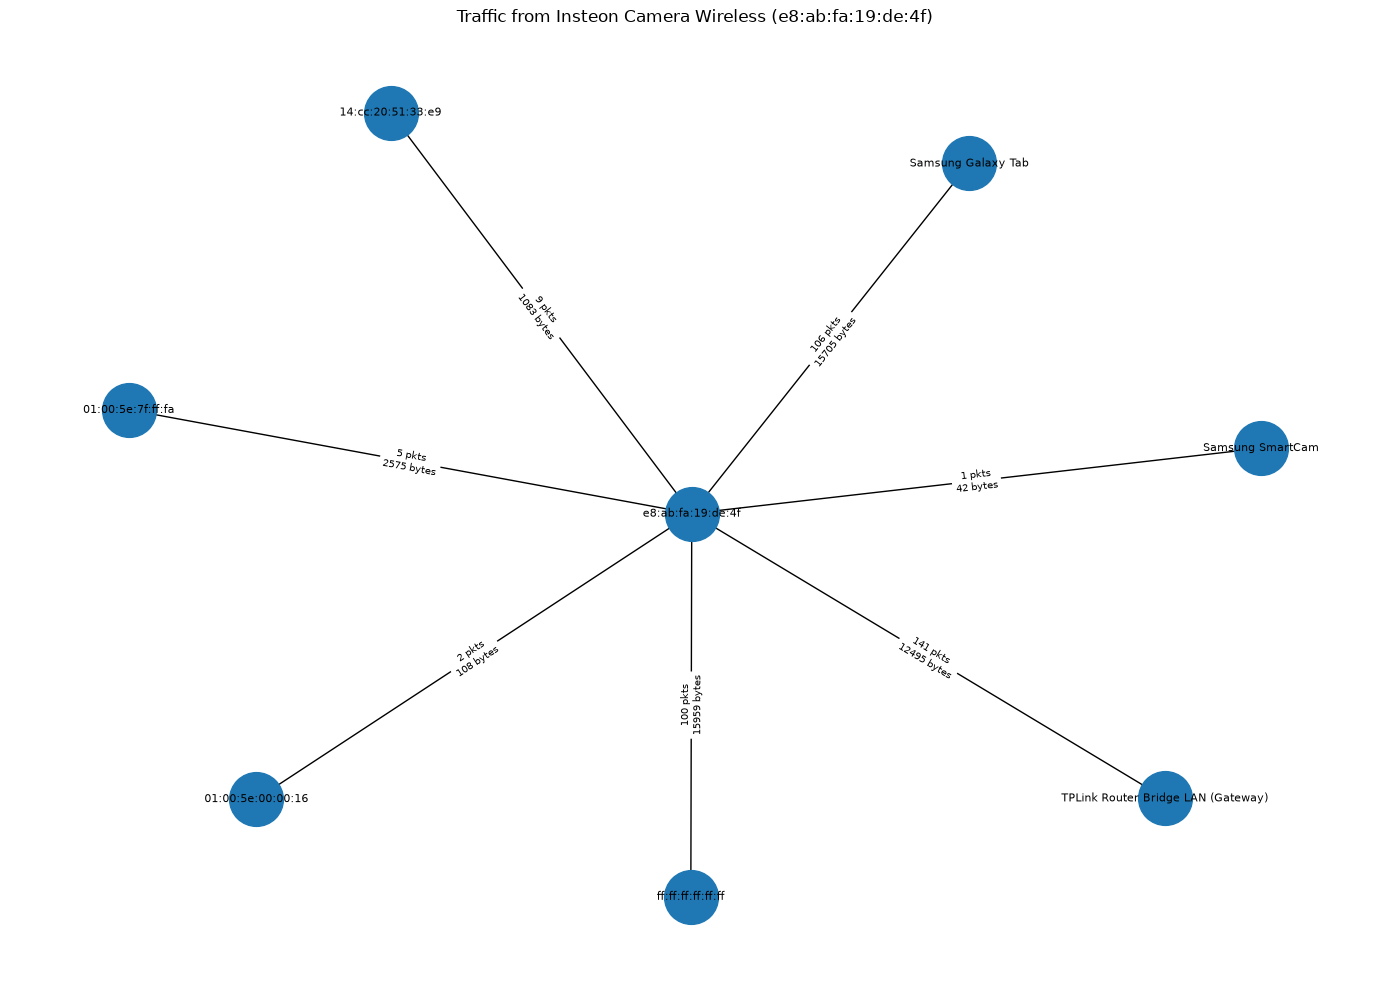

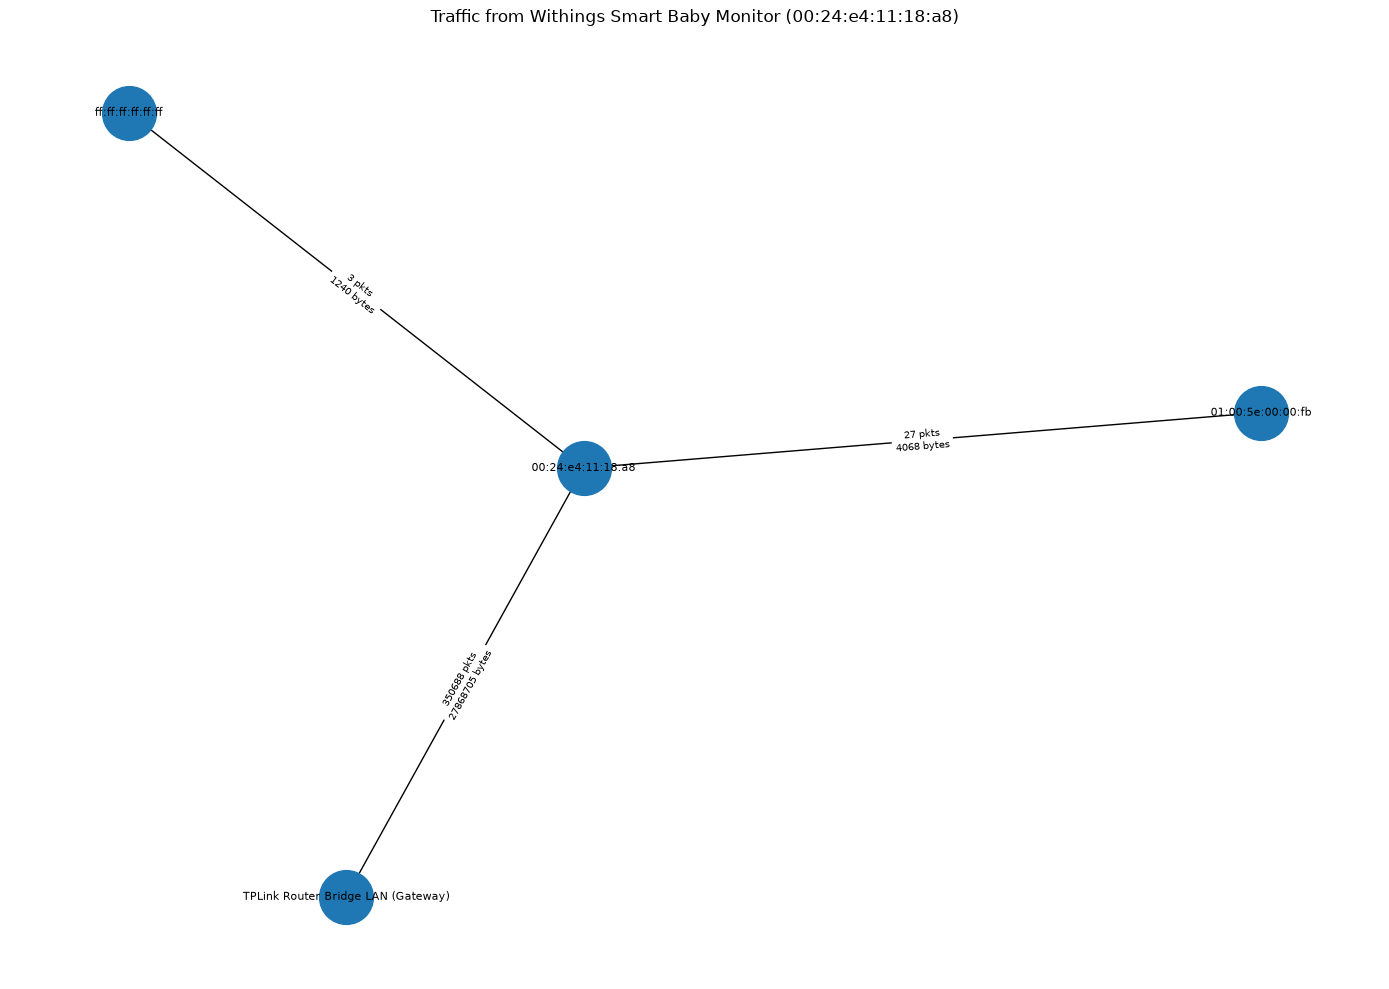

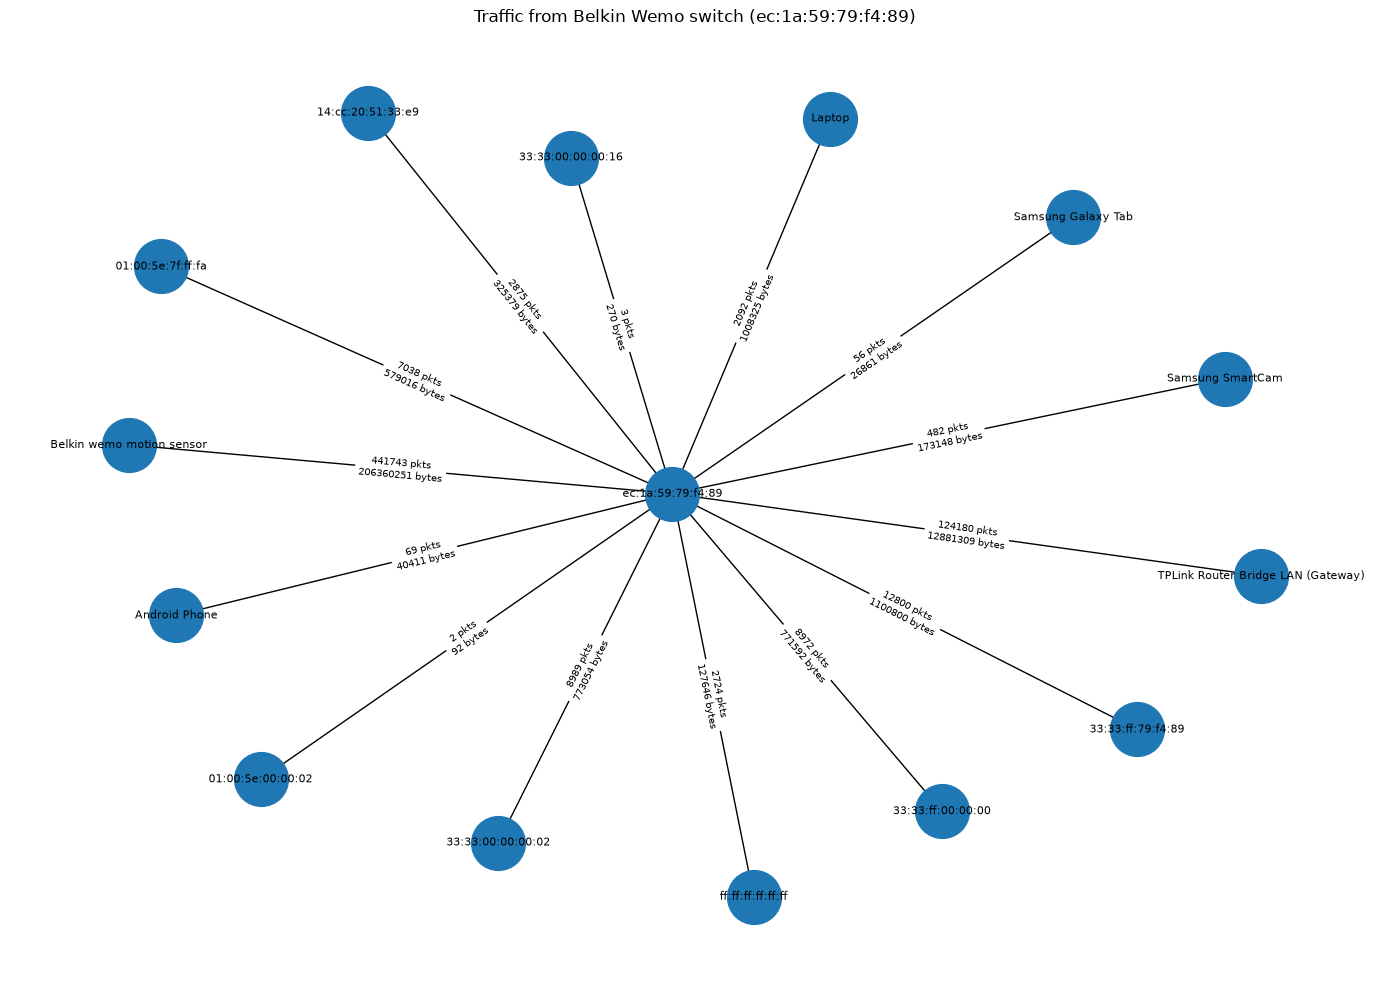

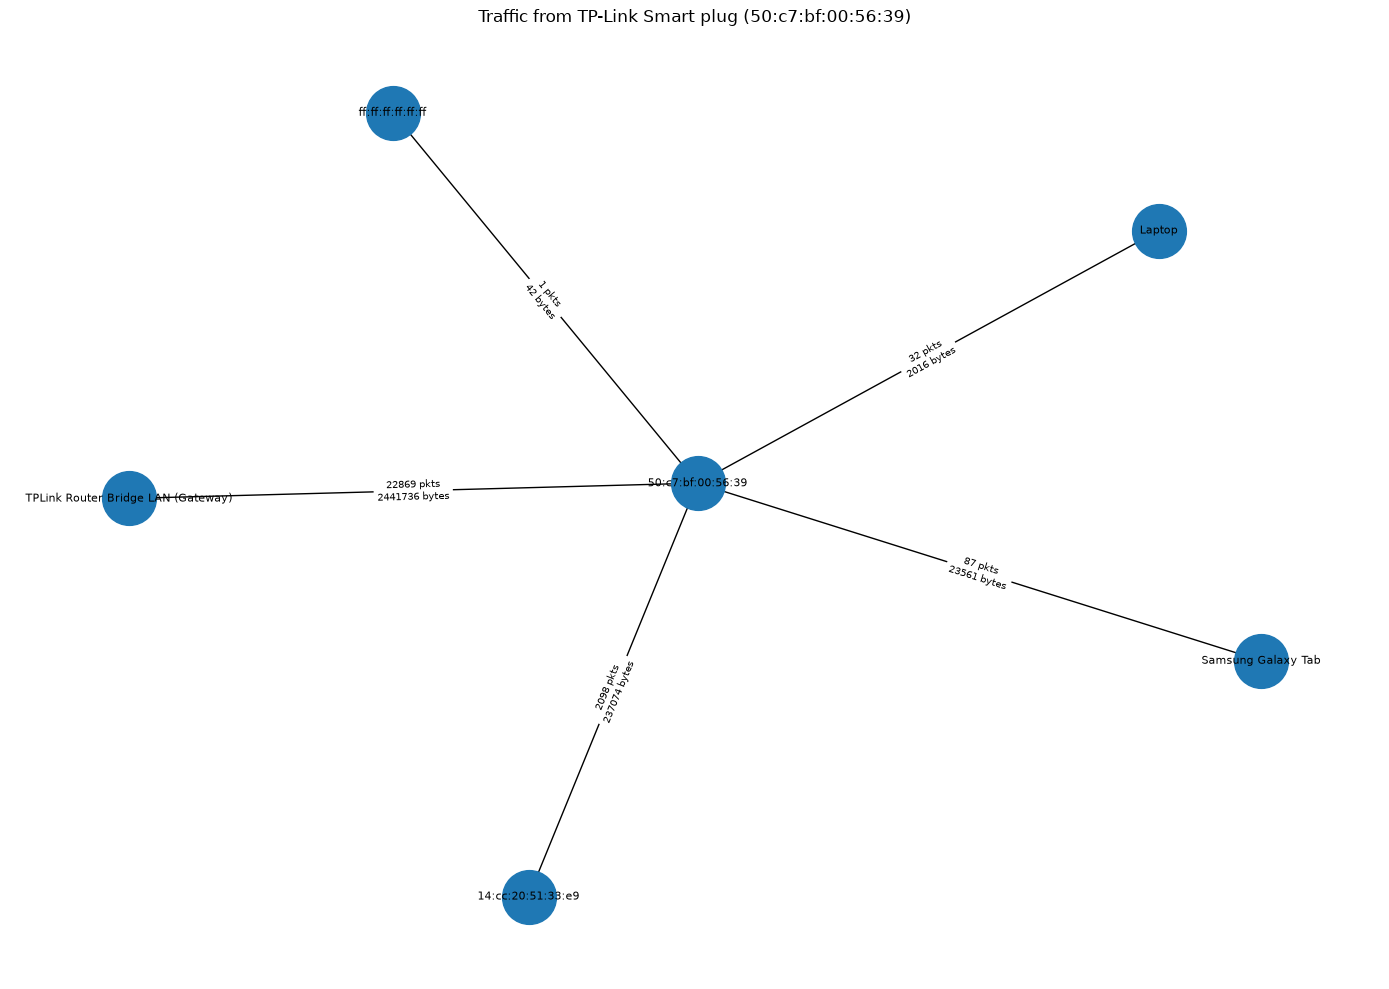

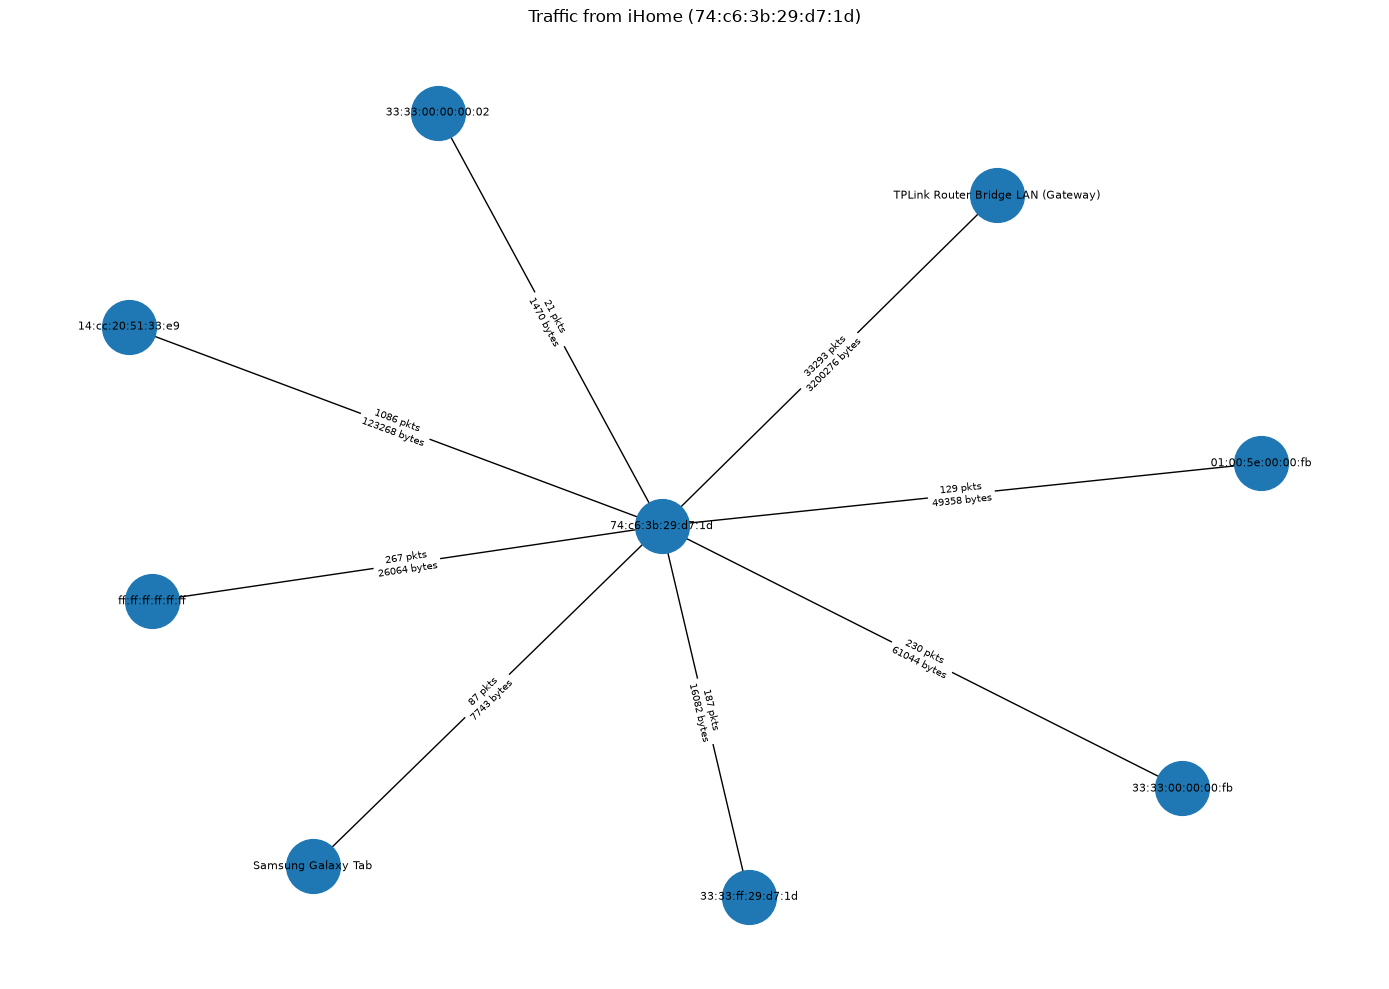

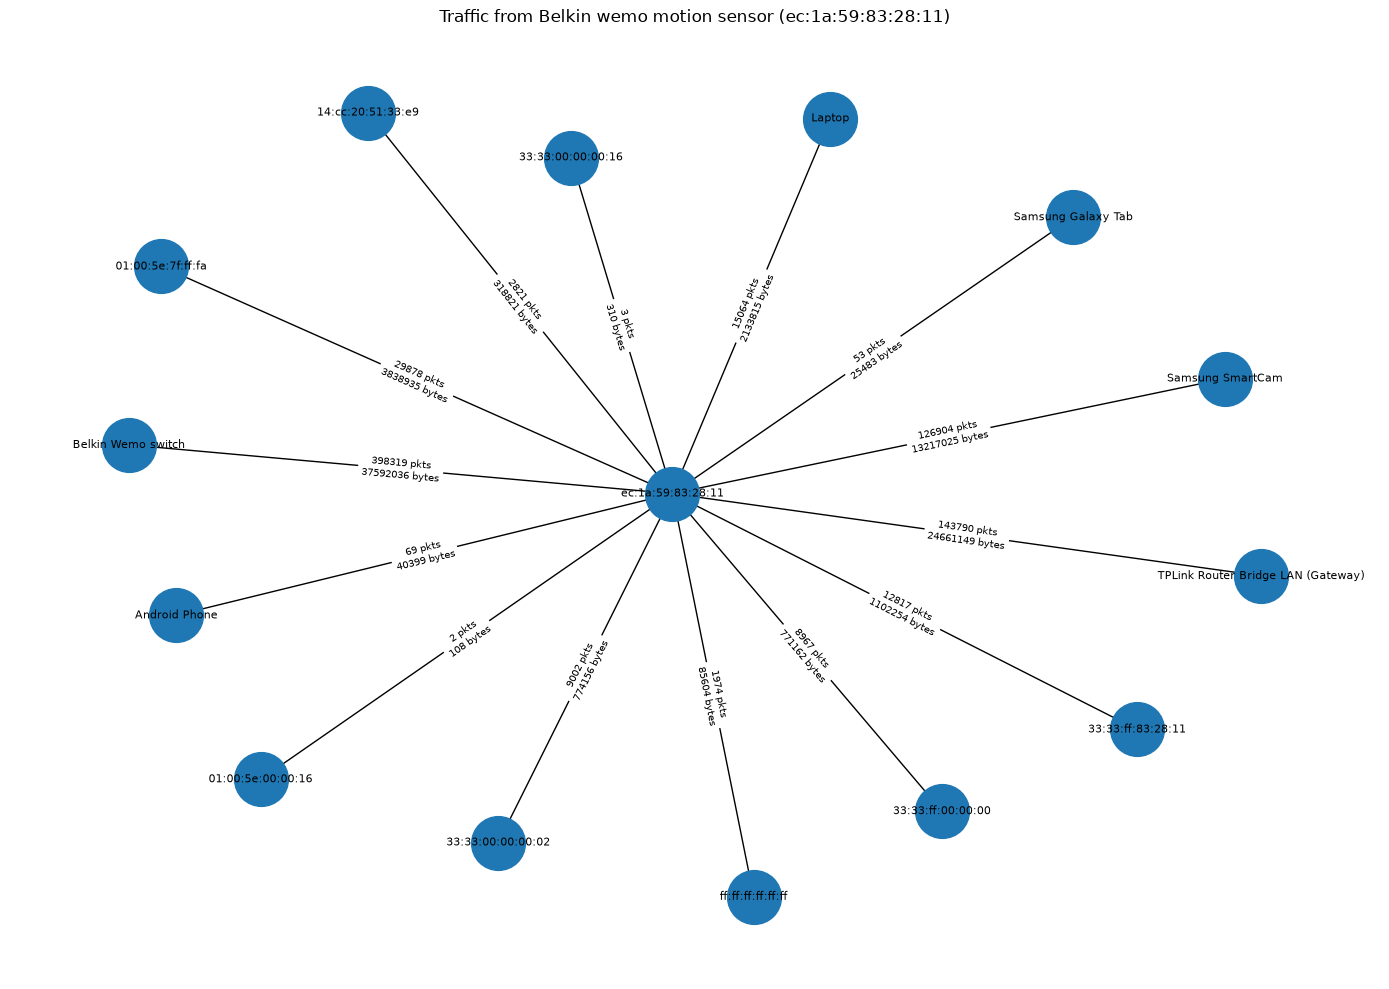

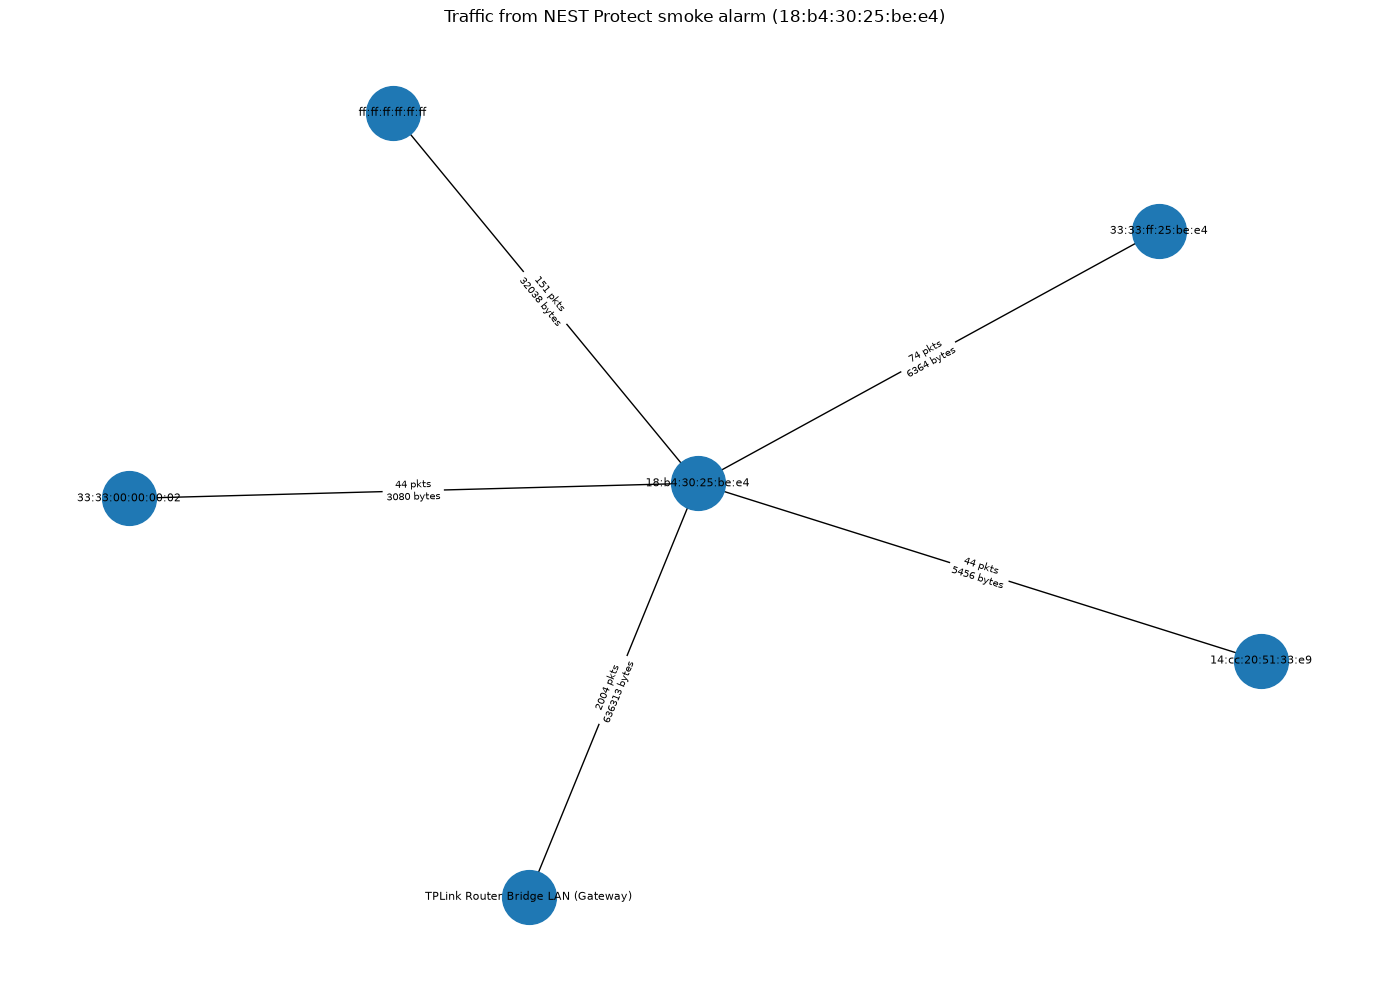

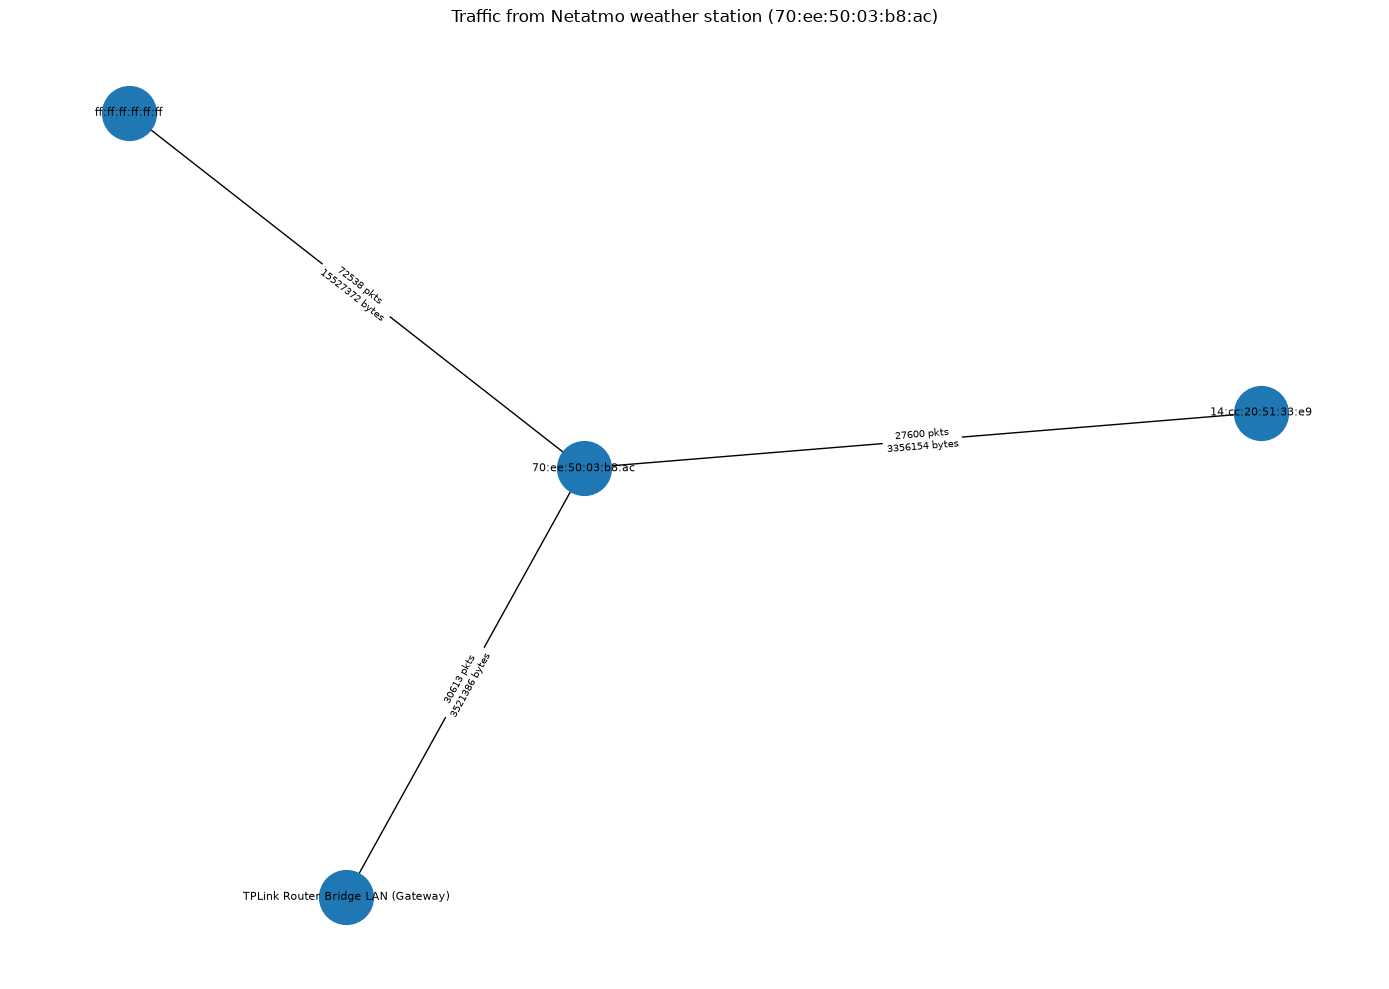

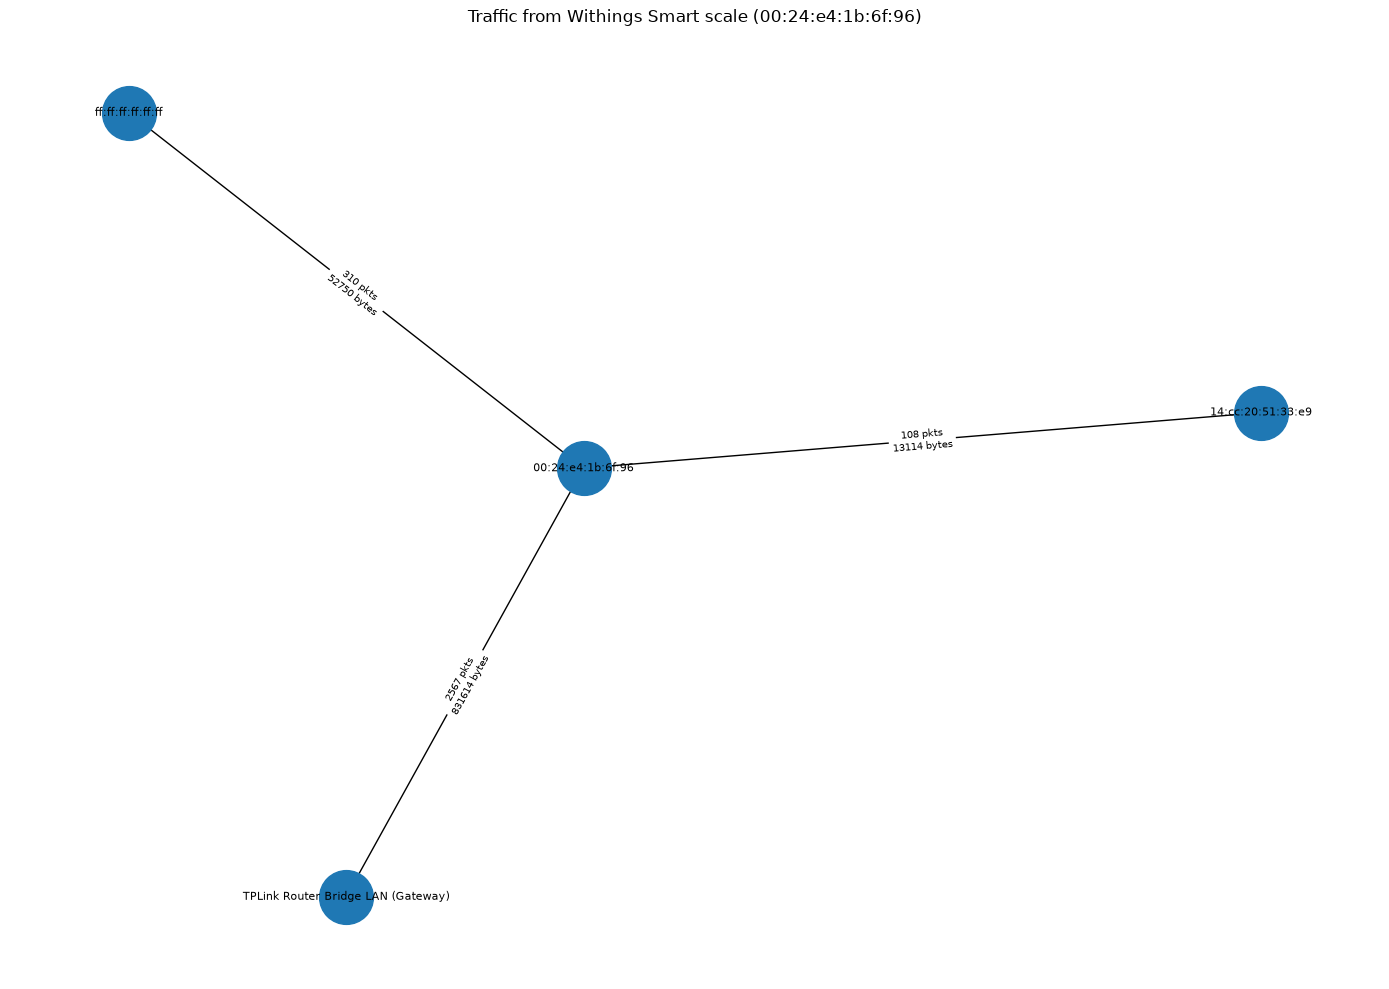

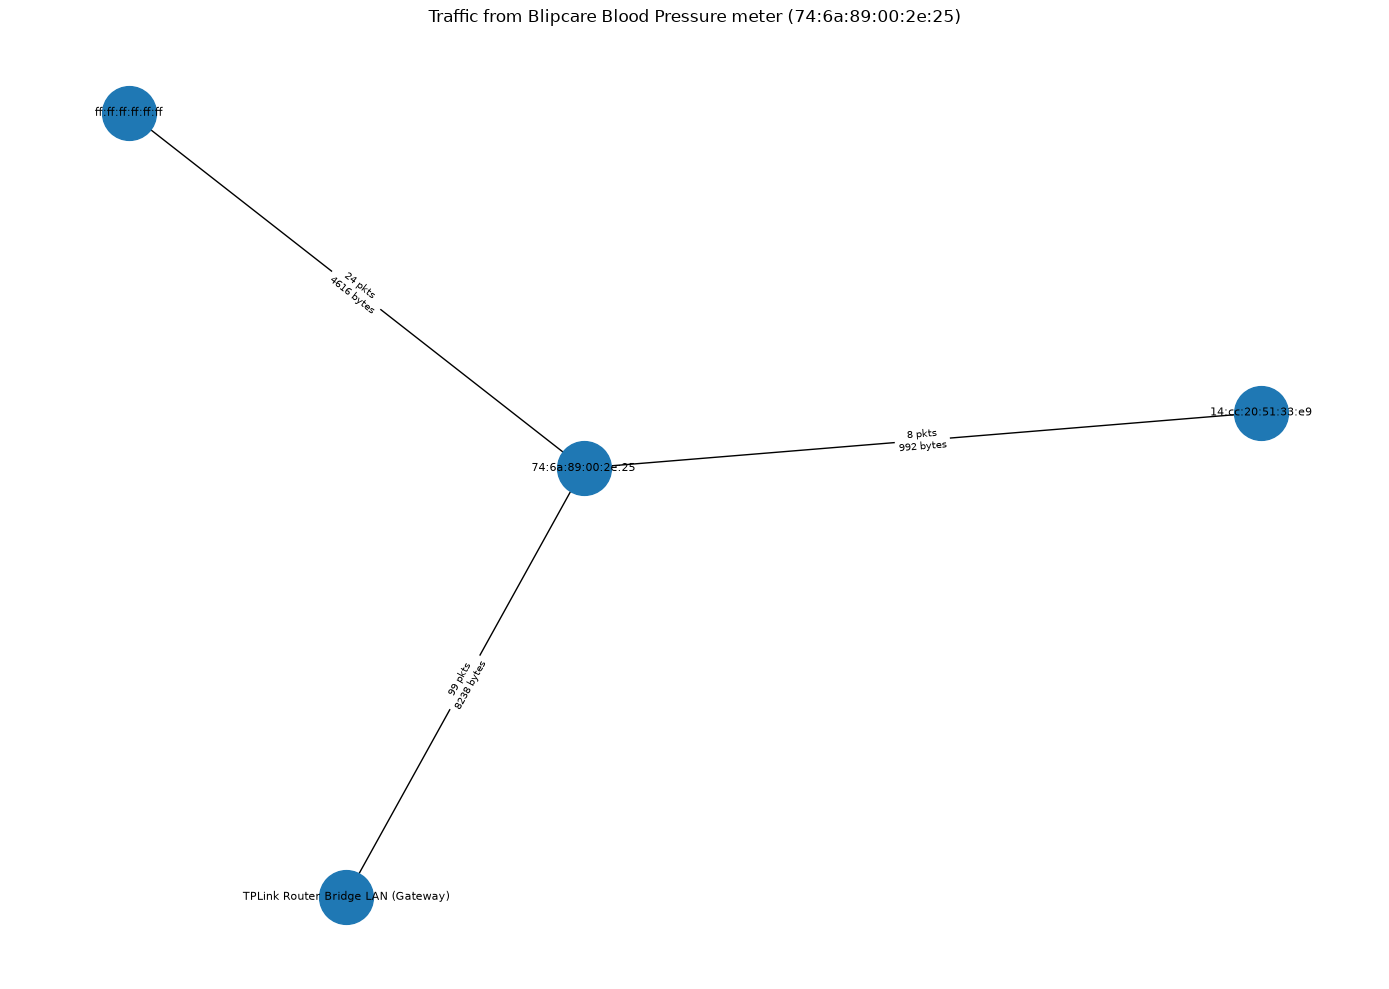

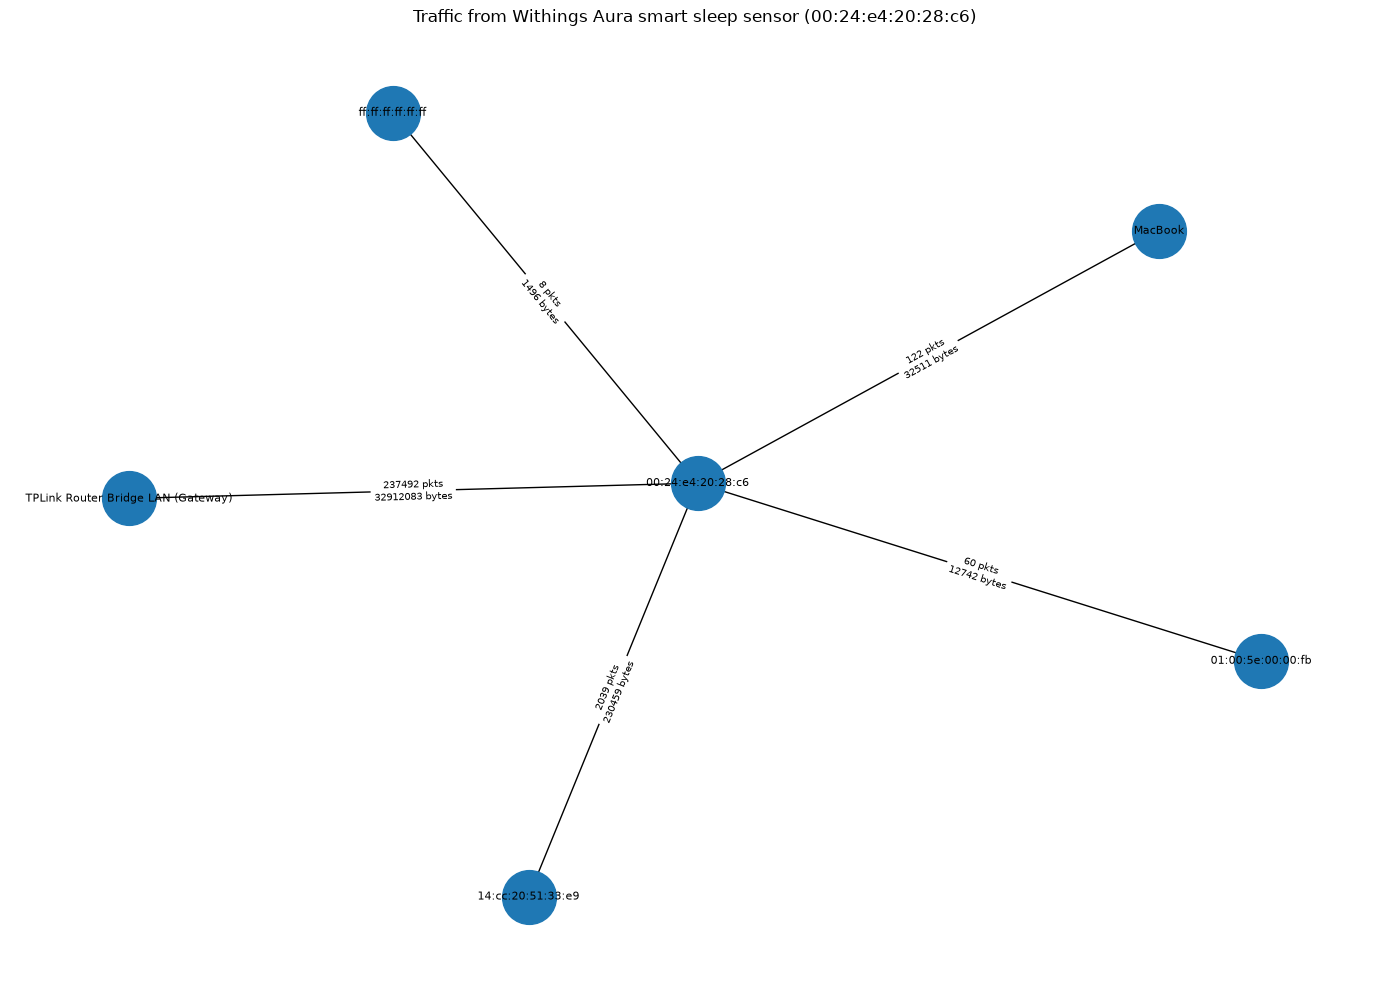

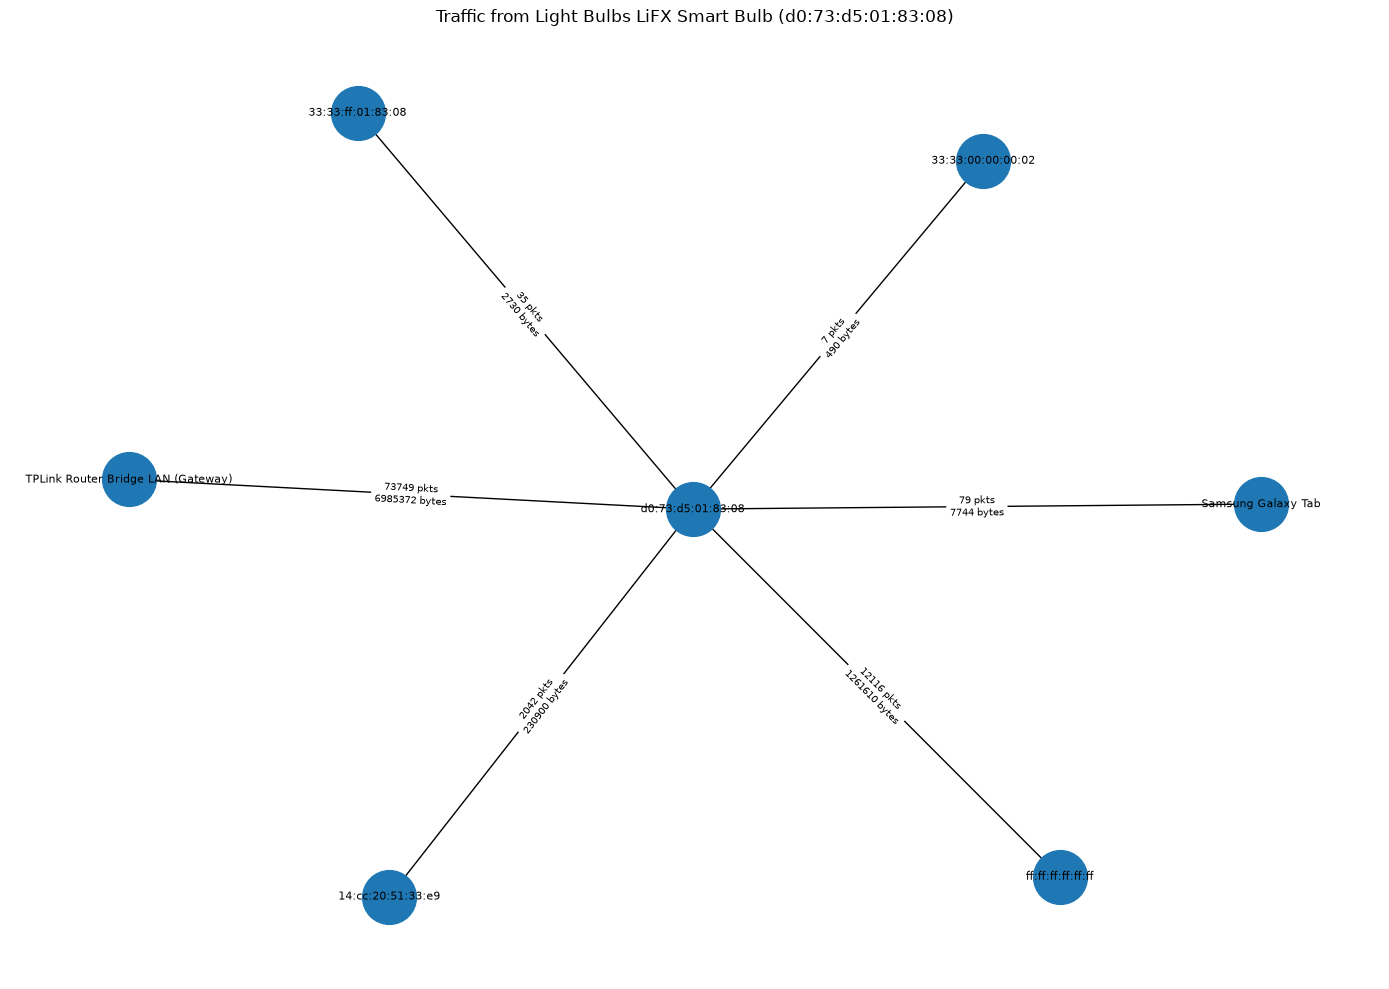

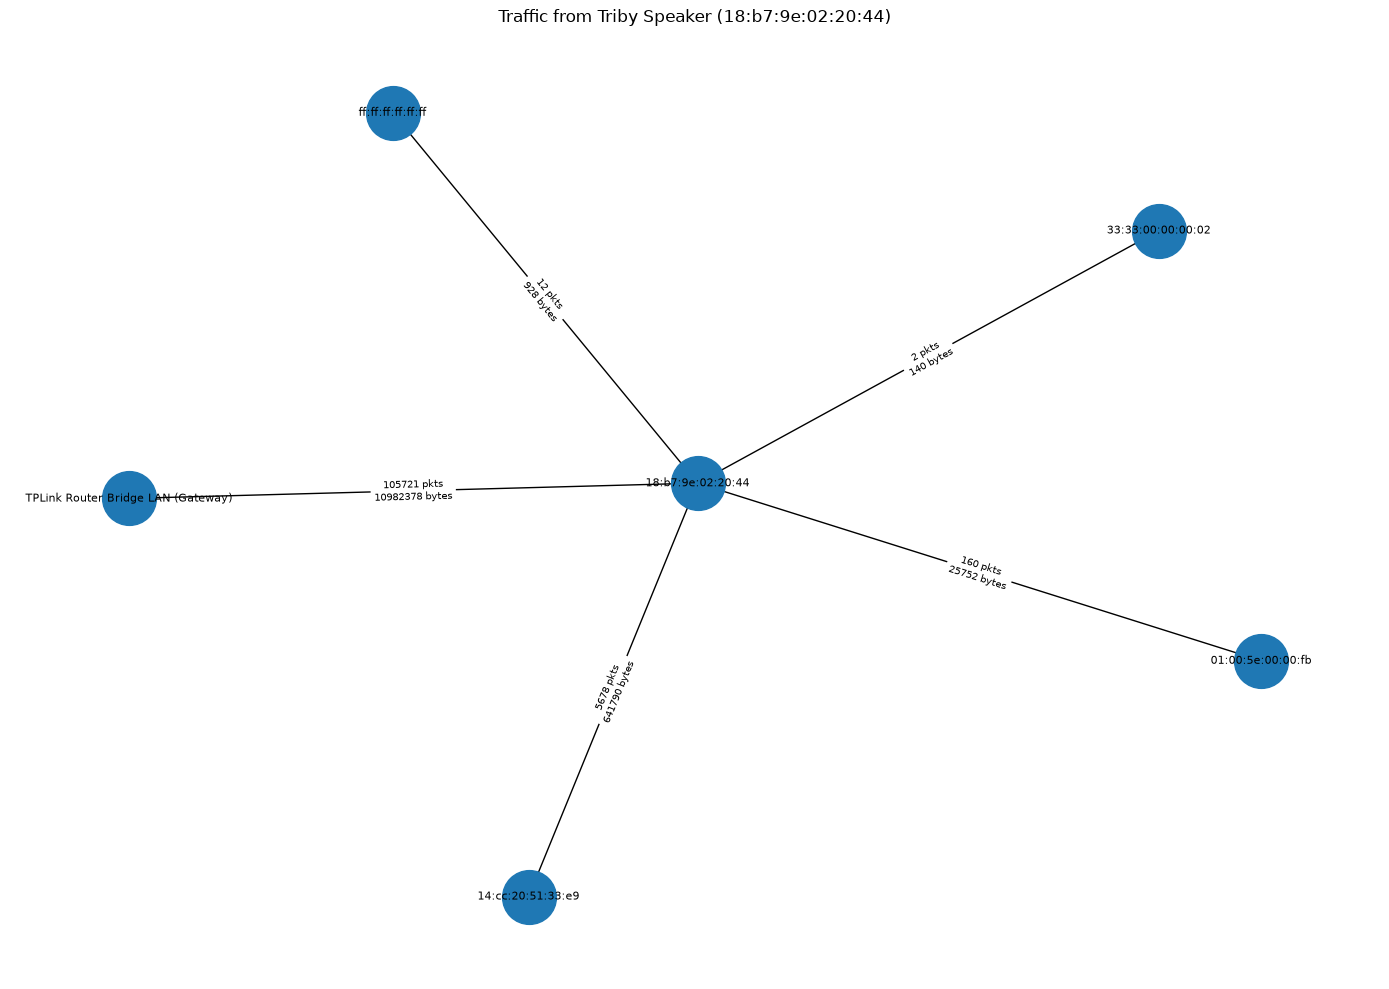

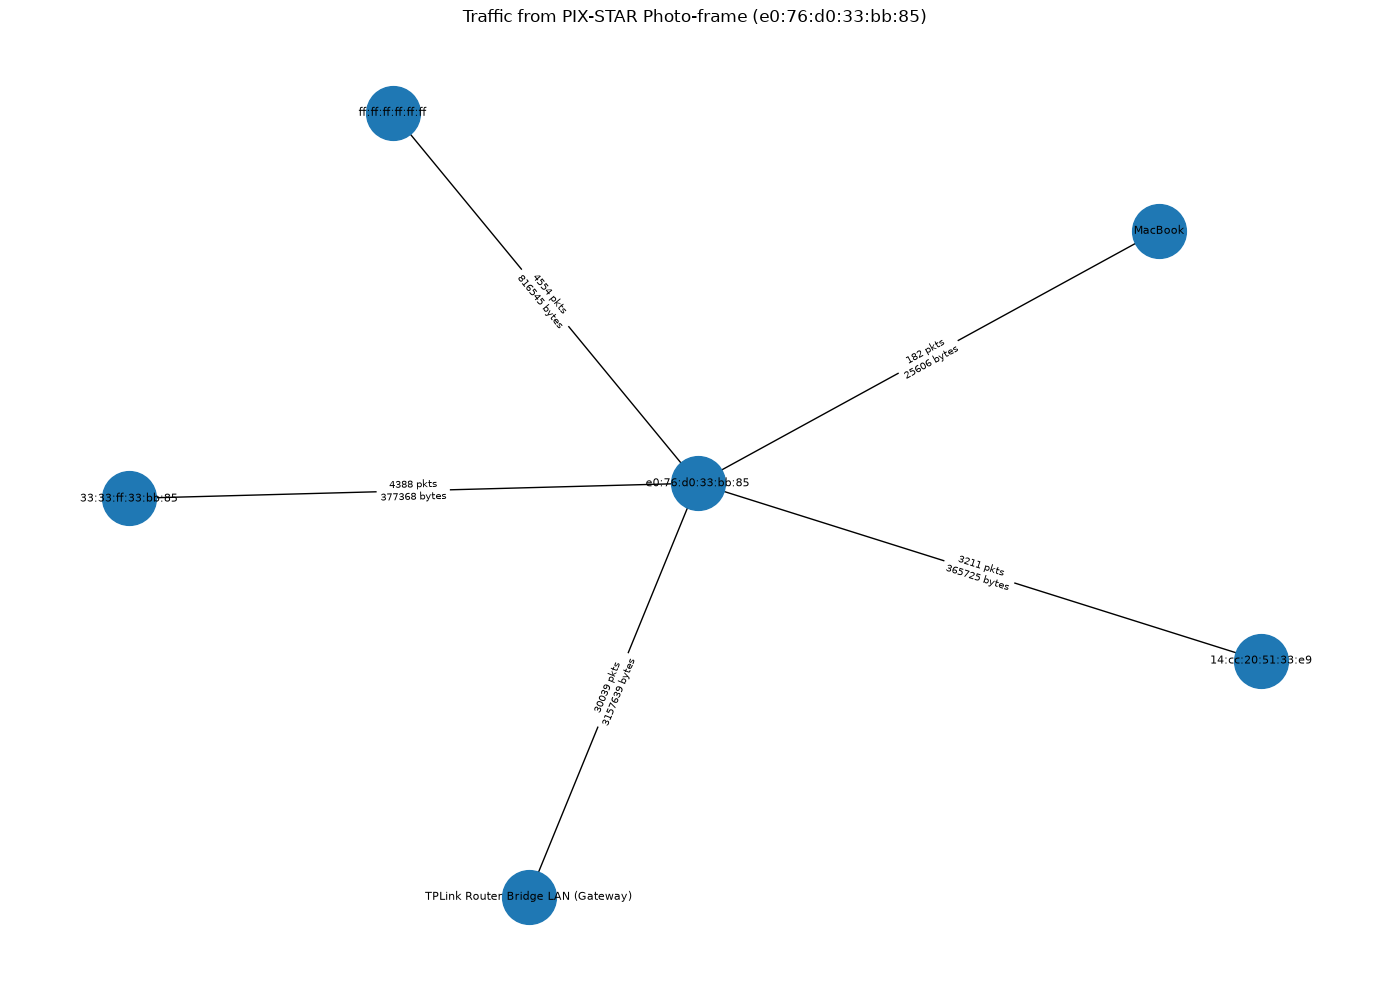

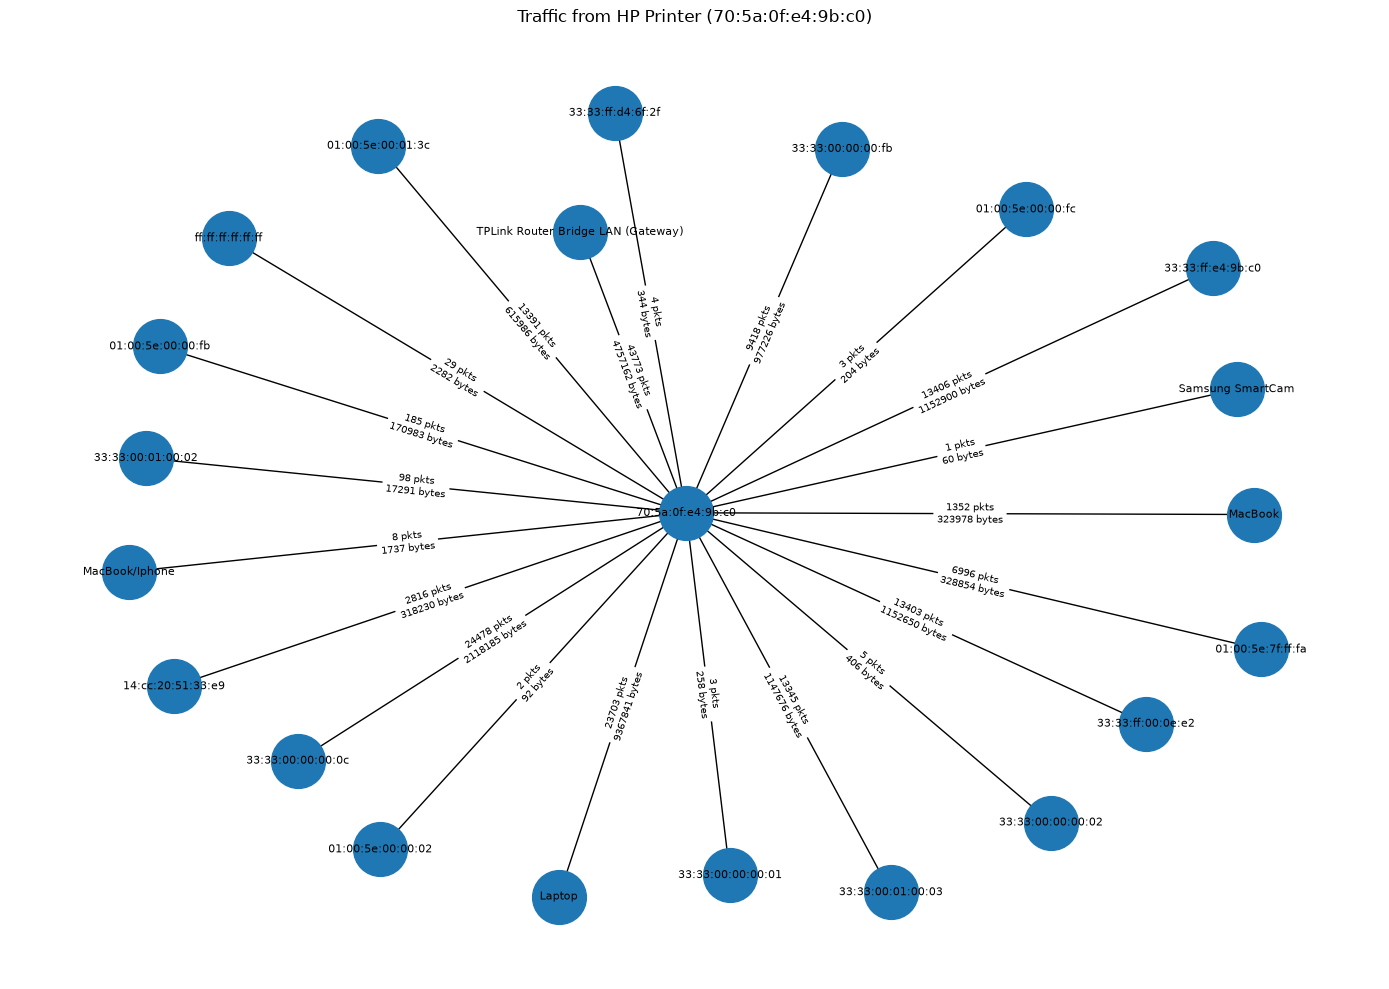

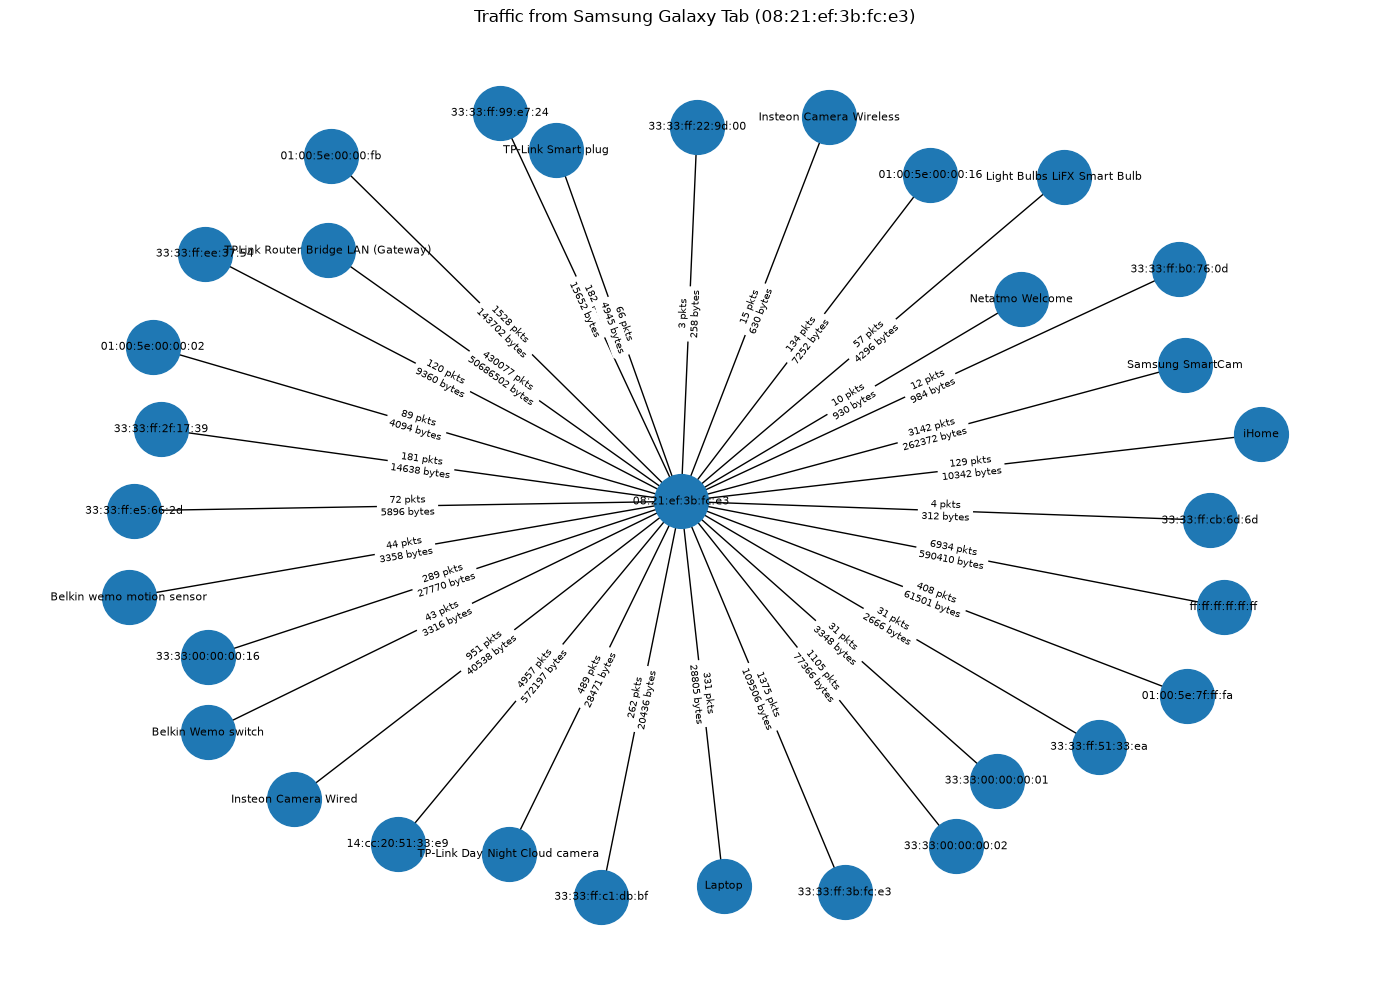

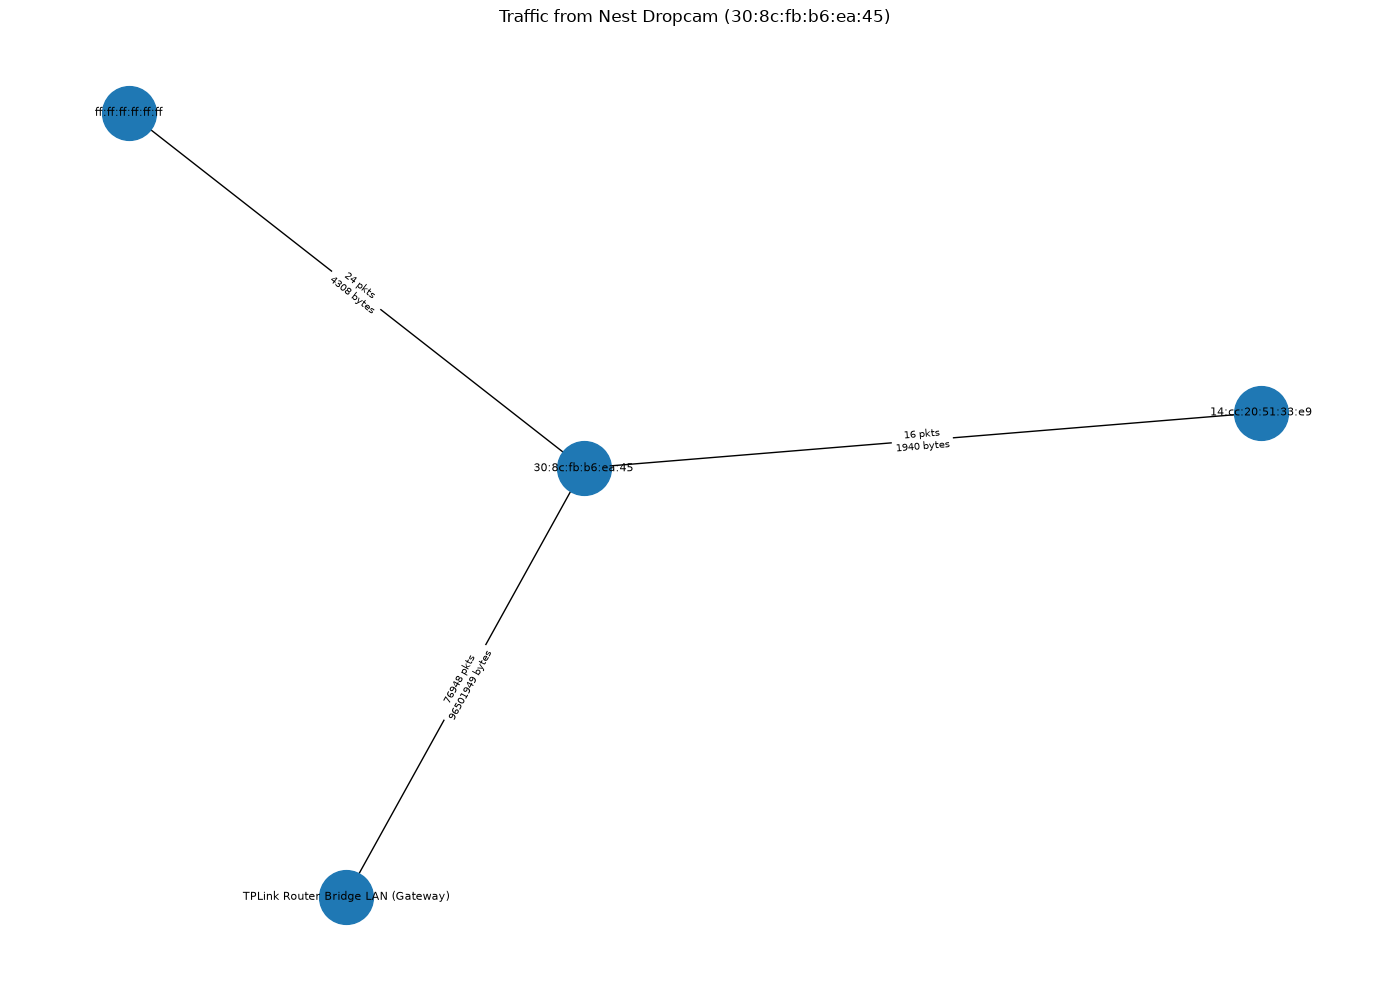

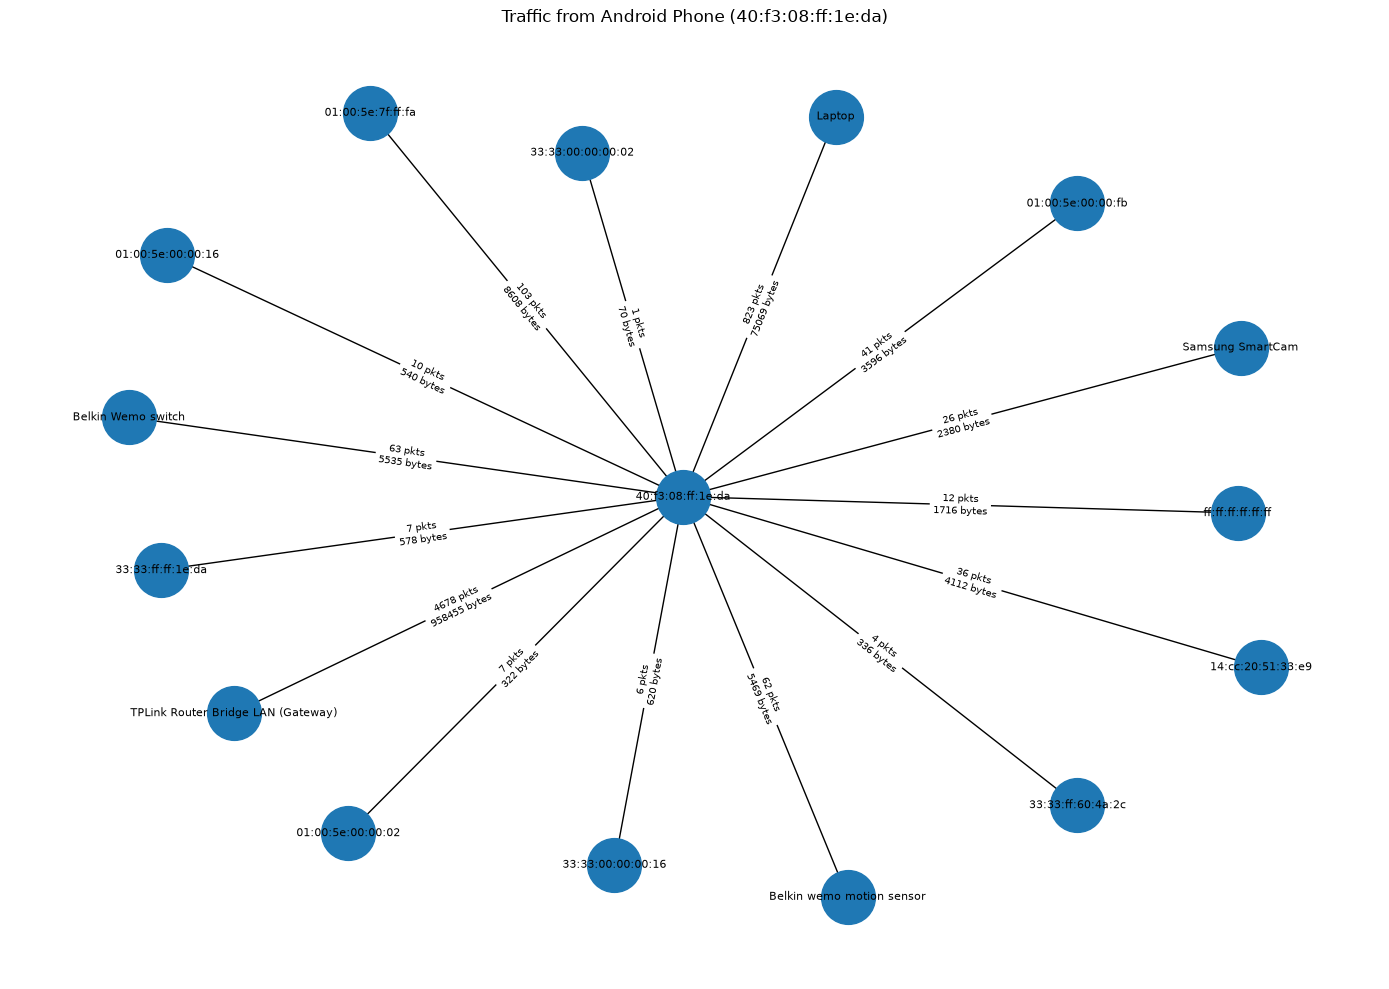

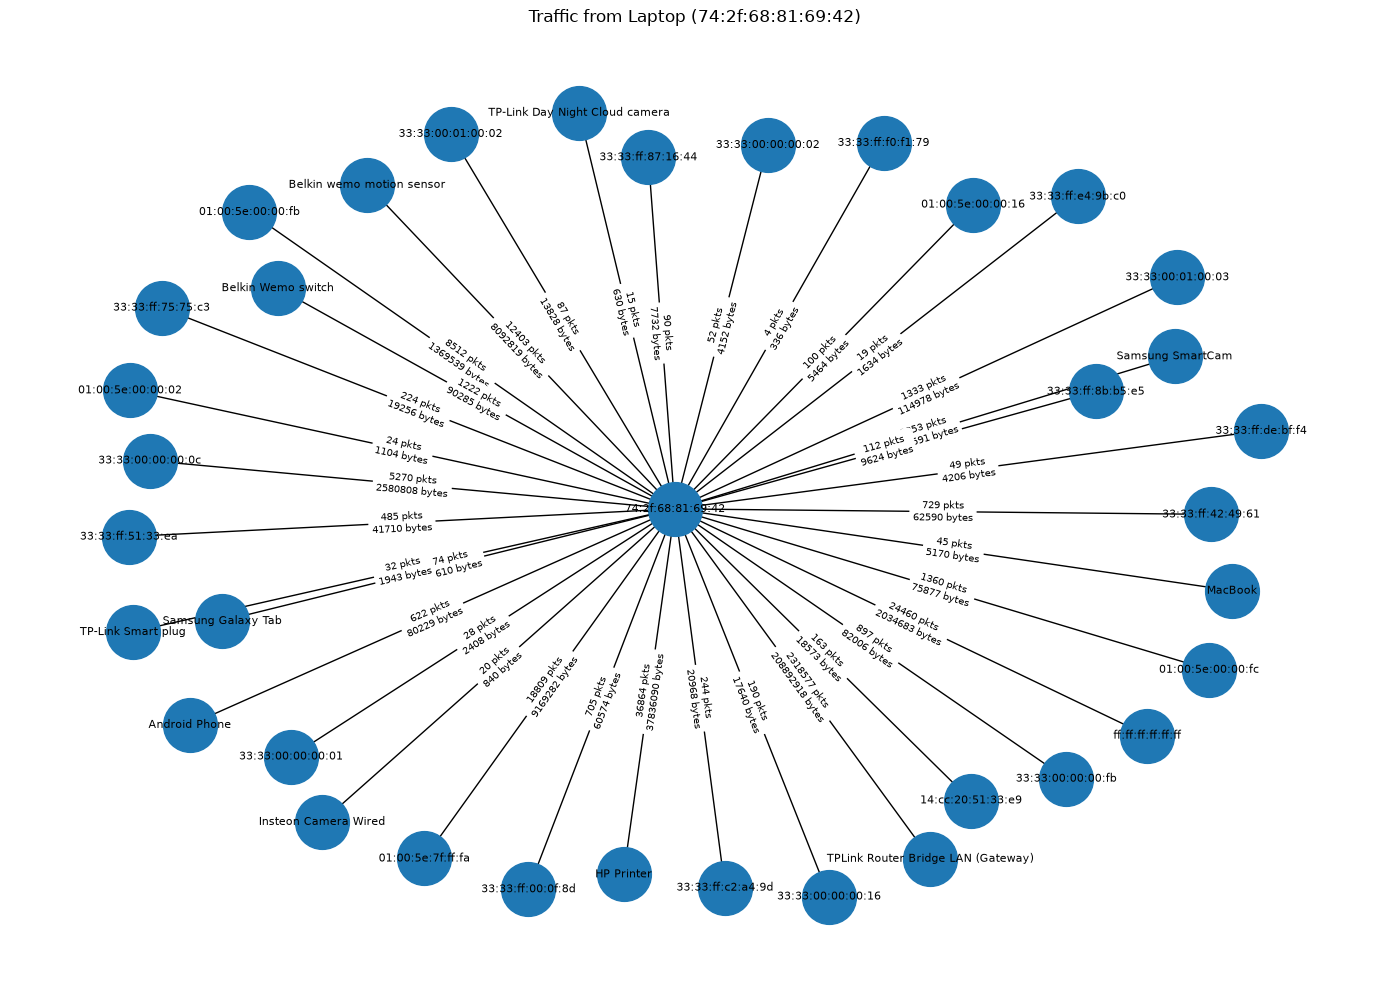

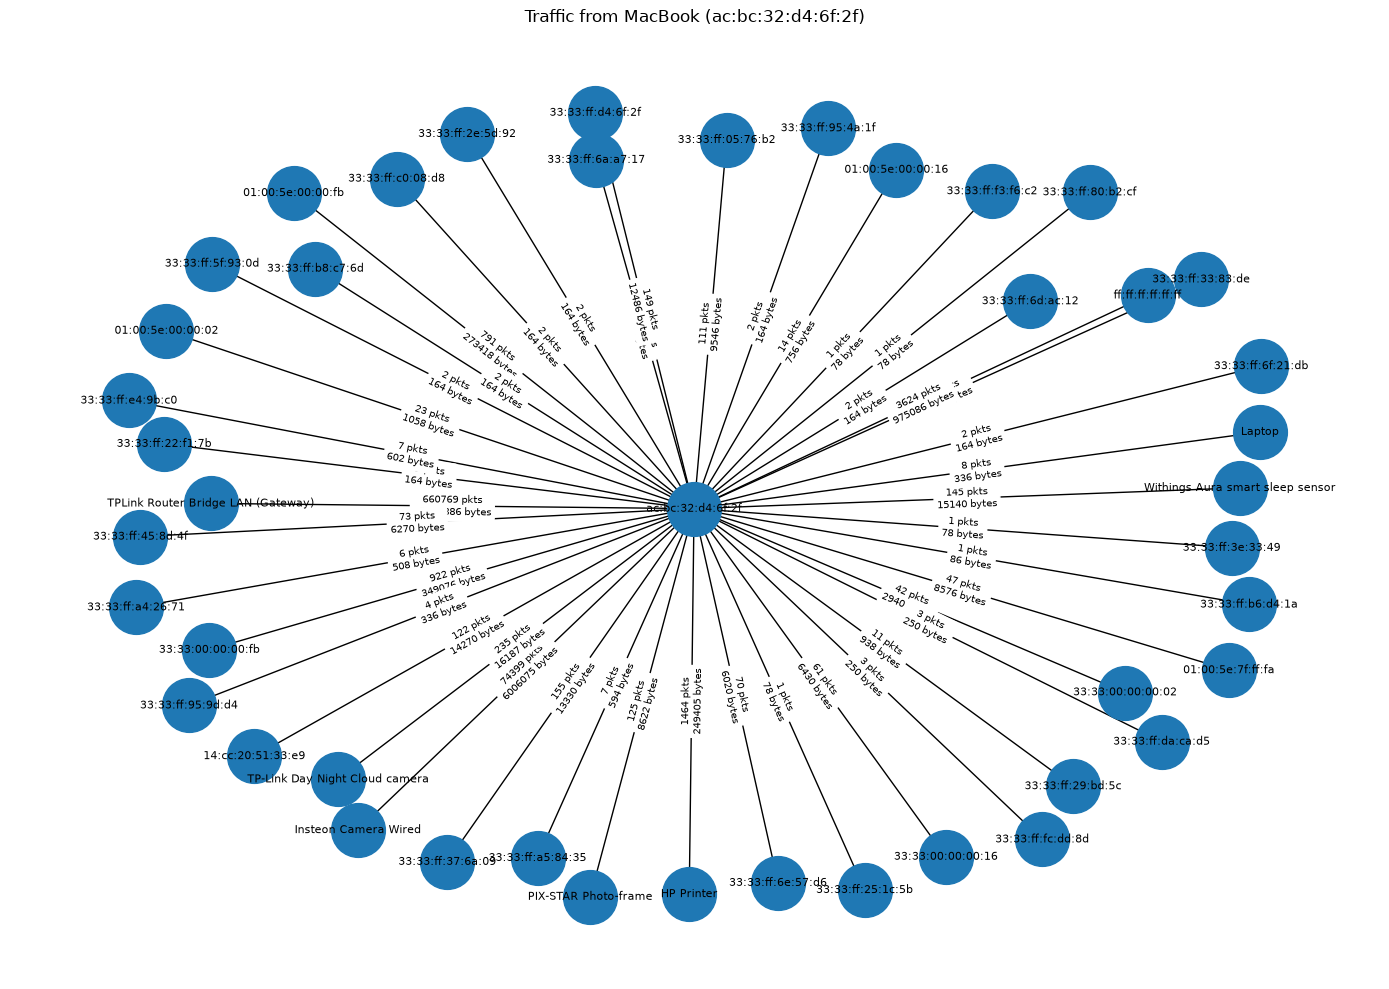

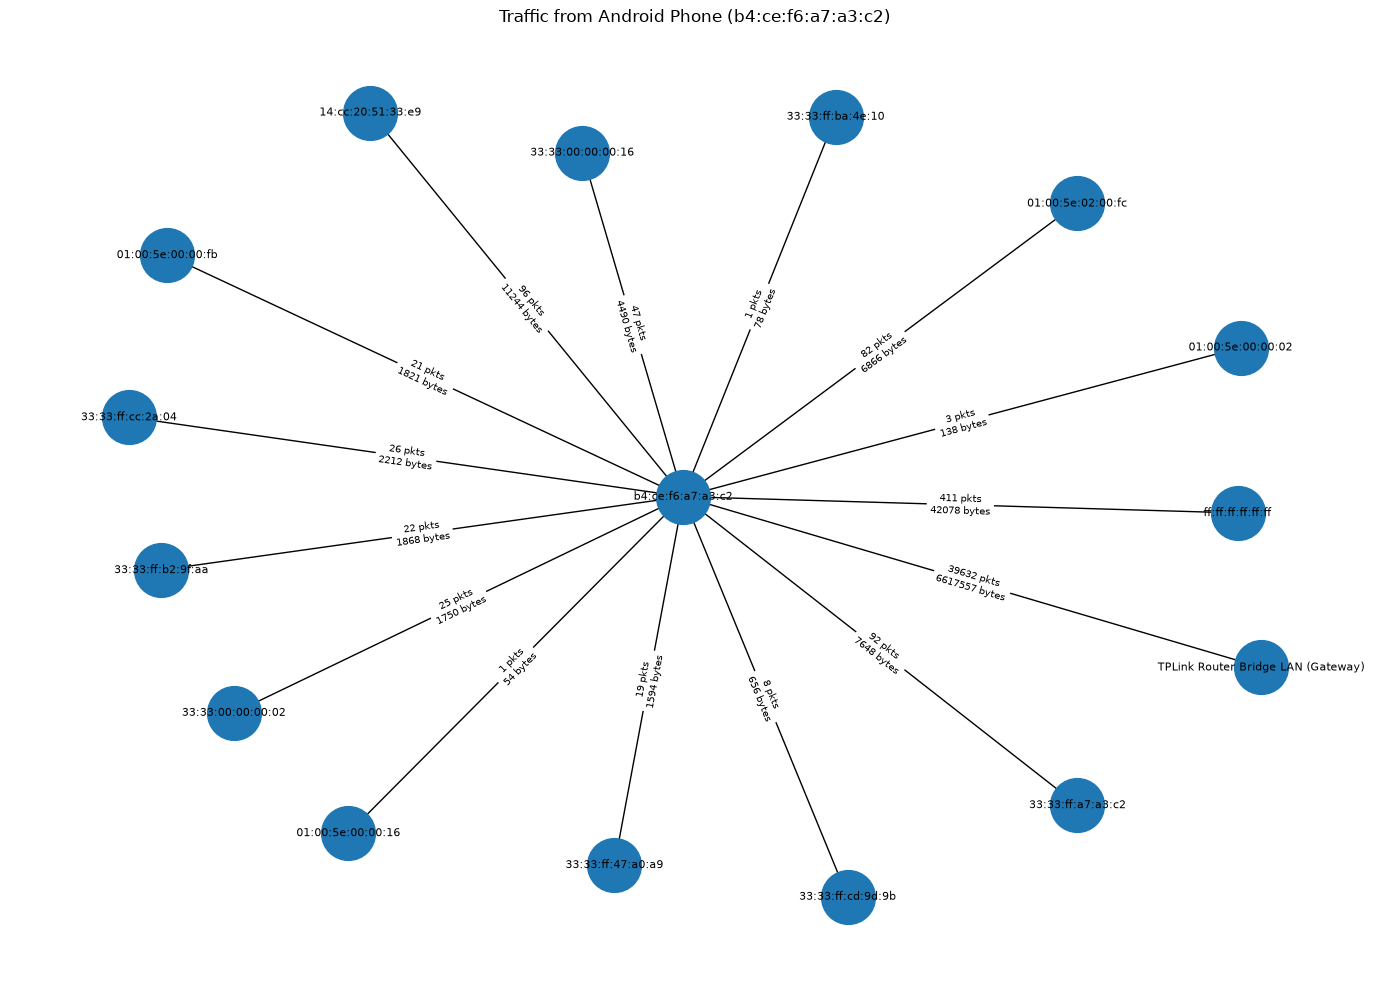

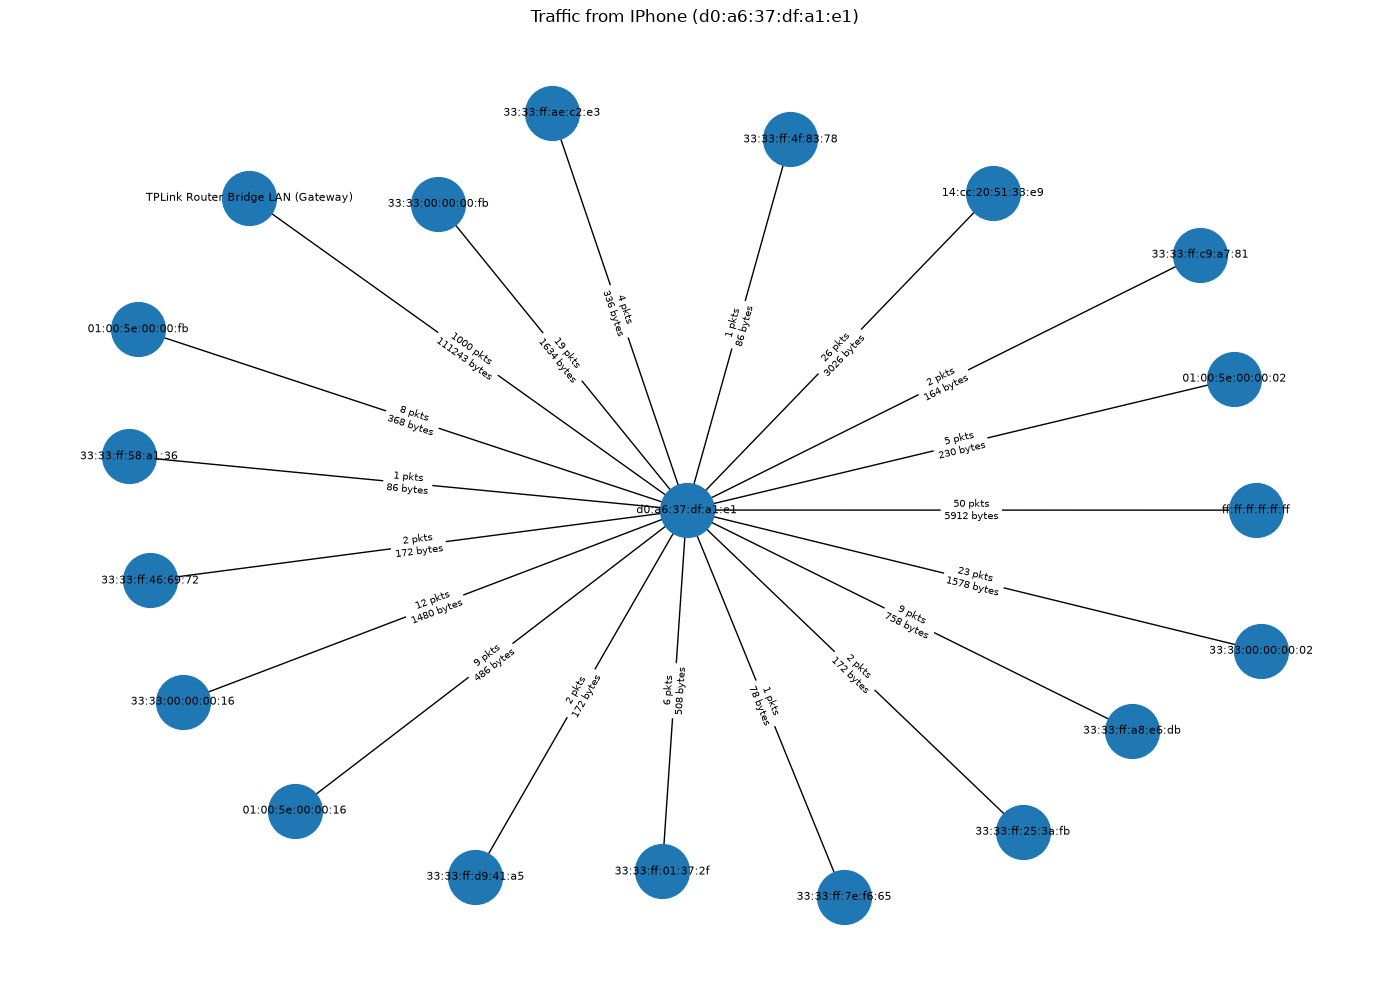

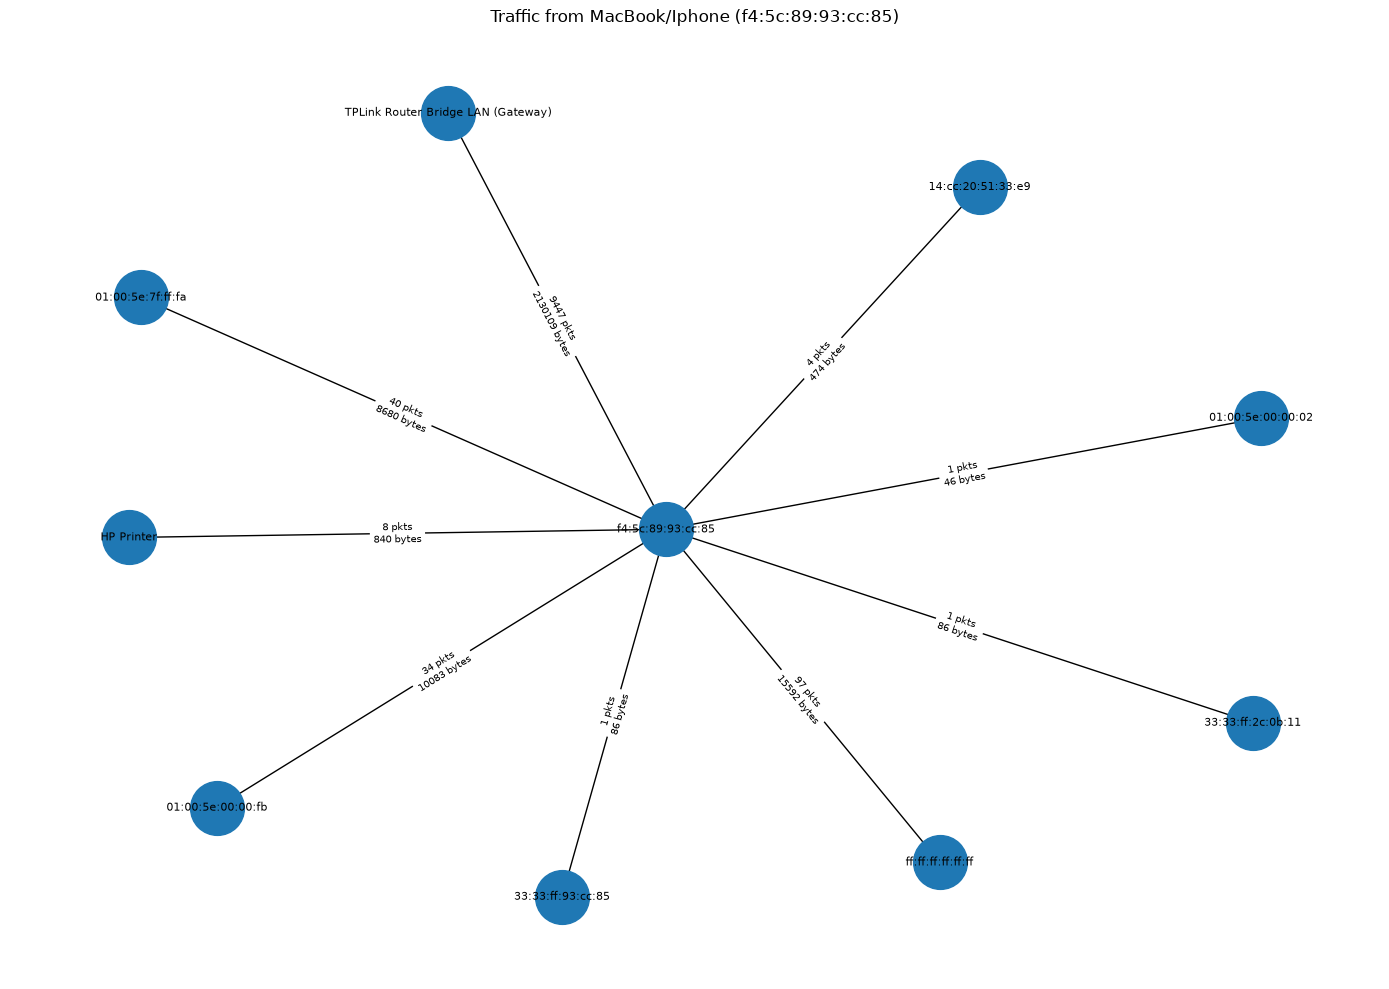

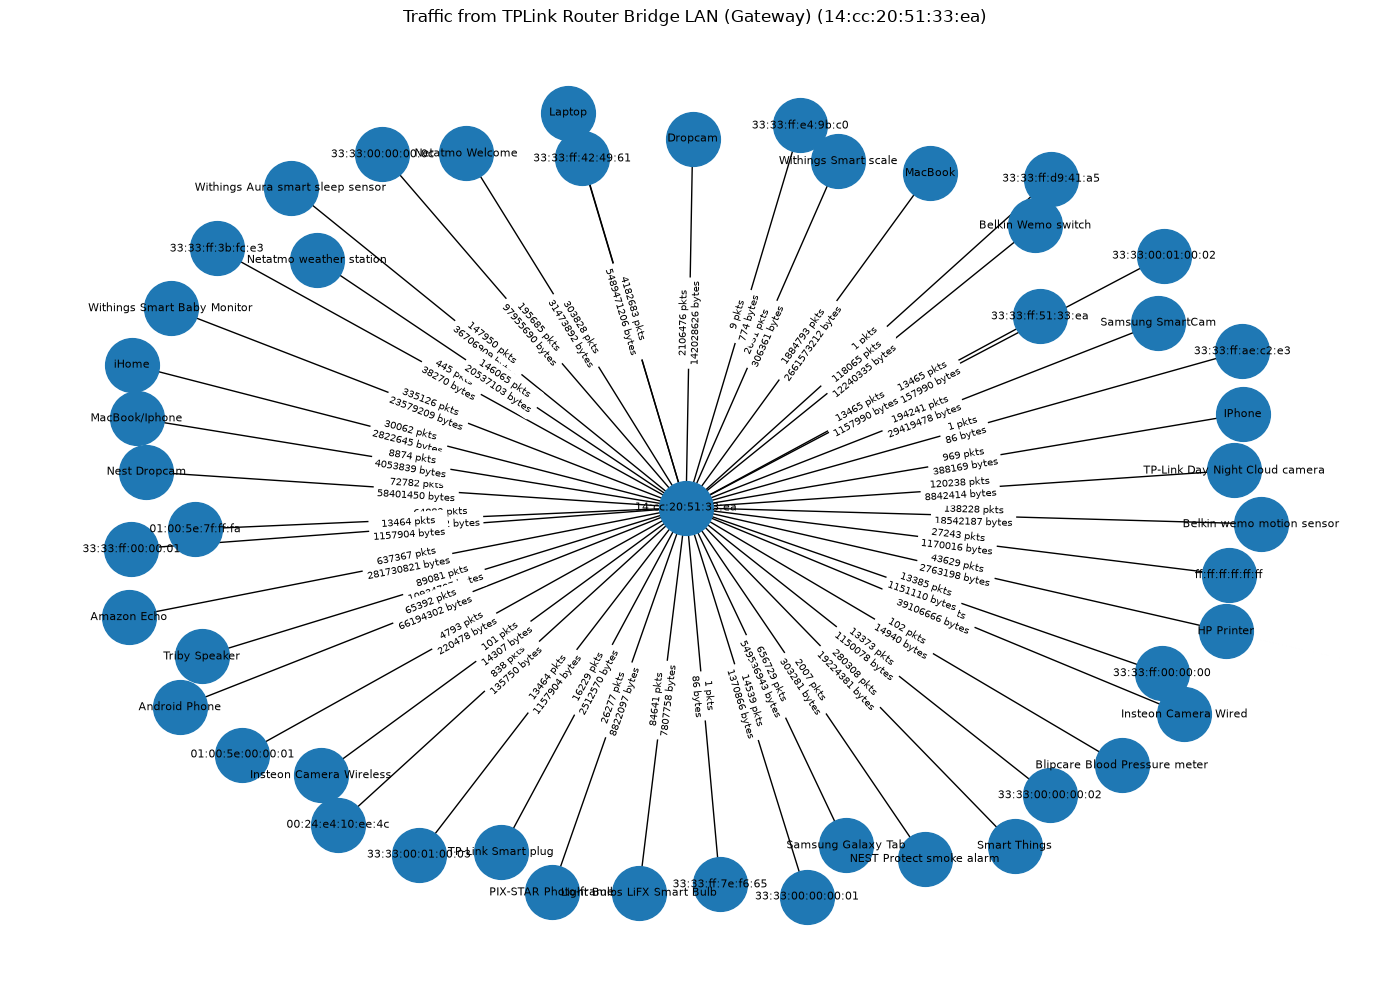

In [12]:
import networkx as nx
for mac in device_dict_1:
    source_mac = mac

    agg_df = (
        df[df["eth.src"] == source_mac]
        .dropna(subset=["eth.dst"])
        .groupby("eth.dst", observed=True)
        .agg(
            packet_count=("frame.number", "count"),
            total_bytes=("frame.len", "sum")
        )
        .reset_index()
        .sort_values("packet_count", ascending=False)
    )

    agg_df = (
        df[df["eth.src"] == source_mac]
        .dropna(subset=["eth.dst"])
        .groupby("eth.dst", observed=True)
        .agg(
            packet_count=("frame.len", "size"),
            total_bytes=("frame.len", "sum")
        )
        .reset_index()
    )

    G = nx.DiGraph()

    # Source node
    G.add_node(source_mac)

    # Destination nodes + edges
    for _, row in agg_df.iterrows():
        dst = row["eth.dst"]
        if row["eth.dst"] in device_dict_1:
            dst = device_dict_1[row["eth.dst"]]["device_name"]
        

        G.add_edge(
            source_mac,
            dst,
            packet_count=row["packet_count"],
            total_bytes=row["total_bytes"]
        )

    # Layout
    pos = nx.spring_layout(G, seed=42)

    plt.figure(figsize=(14, 10))

    nx.draw_networkx_nodes(
        G,
        pos,
        node_size=1500
    )

    nx.draw_networkx_edges(
        G,
        pos,
        arrows=True,
        arrowsize=20
    )

    nx.draw_networkx_labels(
        G,
        pos,
        font_size=8
    )

    # Edge labels
    edge_labels = {
        (u, v): f"{data['packet_count']} pkts\n{data['total_bytes']} bytes"
        for u, v, data in G.edges(data=True)
    }

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        font_size=7
    )

    plt.title(f"Traffic from {device_dict_1[source_mac]['device_name']} ({source_mac})")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
        
        